In [1]:
import pandas as pd
import glob
files = glob.glob("Network_Intrusion_Dataset/*.csv")
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score, silhouette_score

In [2]:
pd.set_option ("display.max_columns",100)
pd.set_option ("display.max_rows",100)

In [3]:
parts = []

for f in files:
    d = pd.read_csv(f,encoding="latin1",low_memory=False)
    d.columns = d.columns.str.strip()
    d["session"] = os.path.basename(f).replace(".pcap_ISCX.csv","")
    print(f"{d['session'].iloc[0]:<45}{d.shape}")
    parts.append(d)

df = pd.concat(parts,ignore_index=True)
del parts

df["Label"] = df["Label"].str.replace(r"[^\x00-\x7F]+", "-", regex=True).str.strip()
num_cols = df.select_dtypes("number").columns
df[num_cols] = df[num_cols].astype("float32")
print("Combined:",df.shape)

Friday-WorkingHours-Afternoon-DDos           (225745, 80)
Friday-WorkingHours-Afternoon-PortScan       (286467, 80)
Friday-WorkingHours-Morning                  (191033, 80)
Monday-WorkingHours                          (529918, 80)
Thursday-WorkingHours-Afternoon-Infilteration(288602, 80)
Thursday-WorkingHours-Morning-WebAttacks     (170366, 80)
Tuesday-WorkingHours                         (445909, 80)
Wednesday-workingHours                       (692703, 80)
Combined: (2830743, 80)


Label,BENIGN,Bot,DDoS,DoS GoldenEye,DoS Hulk,DoS Slowhttptest,DoS slowloris,FTP-Patator,Heartbleed,Infiltration,PortScan,SSH-Patator,Web Attack - Brute Force,Web Attack - Sql Injection,Web Attack - XSS
Destination Port,,,,,,,,,,,,,,,
well-known,0.783,0.000,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.157,1.0,1.0,1.0,1.0
registered,0.085,0.768,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.788,0.0,0.0,0.0,0.0
dynamic,0.132,0.232,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.055,0.0,0.0,0.0,0.0


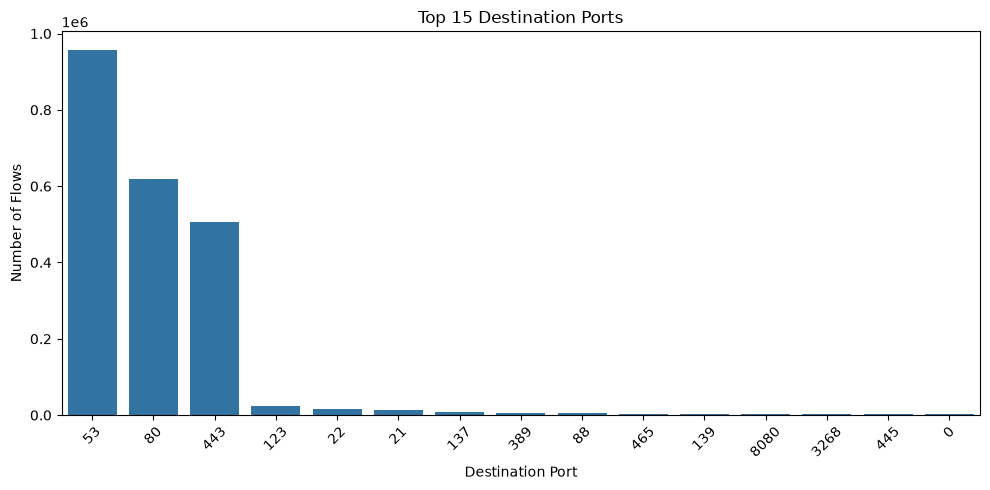

In [4]:
# Protocol distribution by traffic class
if "Protocol" in df.columns:
    display(pd.crosstab(df["Protocol"], df["Label"]))

# Destination Port analysis
port = df["Destination Port"].astype(int)

port_group = pd.cut(
    port,
    [-1, 1023, 49151, 65535],
    labels=["well-known", "registered", "dynamic"]
)

display(pd.crosstab(port_group, df["Label"], normalize="columns").round(3))

# Most common destination ports
top_ports = port.value_counts().head(15)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_ports.index.astype(str), y=top_ports.values)
plt.xlabel("Destination Port")
plt.ylabel("Number of Flows")
plt.title("Top 15 Destination Ports")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

                              count     pct
Label                                      
BENIGN                      2273097  80.300
DoS Hulk                     231073   8.163
PortScan                     158930   5.614
DDoS                         128027   4.523
DoS GoldenEye                 10293   0.364
FTP-Patator                    7938   0.280
SSH-Patator                    5897   0.208
DoS slowloris                  5796   0.205
DoS Slowhttptest               5499   0.194
Bot                            1966   0.069
Web Attack - Brute Force       1507   0.053
Web Attack - XSS                652   0.023
Infiltration                     36   0.001
Web Attack - Sql Injection       21   0.001
Heartbleed                       11   0.000


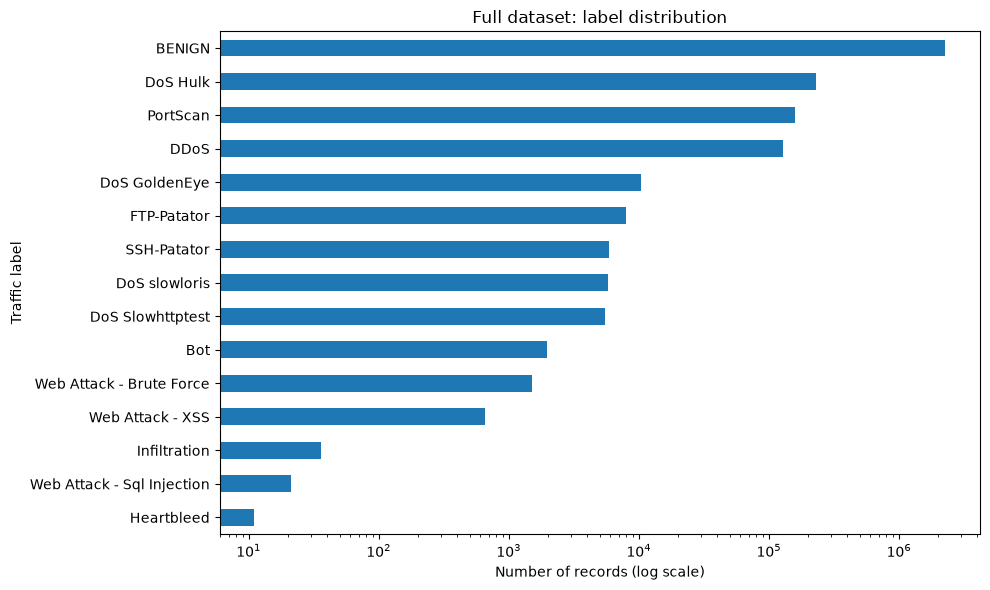

In [5]:
# Row count: Combined shows about 2.83M 
# Column count: 78 Features + Label + session
counts = df["Label"].value_counts()
pct = (counts / len(df) * 100).round(3)
print(pd.DataFrame({"count": counts, "pct": pct}))

plt.figure(figsize=(10, 6))
counts.sort_values().plot.barh(logx=True)
plt.xlabel("Number of records (log scale)")
plt.ylabel("Traffic label")
plt.title("Full dataset: label distribution")
plt.tight_layout(); plt.show()

In [6]:
# Data Quality
# Types and memory
df.info(memory_usage="deep")

# Inf/NaN: Finding in which columns they are in
inf_counts = np.isinf(df[num_cols]).sum()
print("Inf values per column:\n",inf_counts[inf_counts>0],"\n")

df[num_cols] = df[num_cols].replace([np.inf,-np.inf],np.nan)
na =  df[num_cols].isna().sum()
print("NaN values per column (after converting inf):\n",na[na>0],"\n")

# Duplicate rows (ignoring the session column)
n_dup = df.drop(columns="session").duplicated().sum()
print(f"Duplicate rows: {n_dup:,},({n_dup/len(df):.2%})\n")

# Constant columns
nu = df[num_cols].nunique()
print("Constant columns:",nu[nu<=1].index.tolist(),"\n")

# Negative values
neg = (df[num_cols]<0).sum()
print("Columns with negative values:\n",neg[neg>0])

<class 'pandas.DataFrame'>
RangeIndex: 2830743 entries, 0 to 2830742
Data columns (total 80 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   Destination Port             float32
 1   Flow Duration                float32
 2   Total Fwd Packets            float32
 3   Total Backward Packets       float32
 4   Total Length of Fwd Packets  float32
 5   Total Length of Bwd Packets  float32
 6   Fwd Packet Length Max        float32
 7   Fwd Packet Length Min        float32
 8   Fwd Packet Length Mean       float32
 9   Fwd Packet Length Std        float32
 10  Bwd Packet Length Max        float32
 11  Bwd Packet Length Min        float32
 12  Bwd Packet Length Mean       float32
 13  Bwd Packet Length Std        float32
 14  Flow Bytes/s                 float32
 15  Flow Packets/s               float32
 16  Flow IAT Mean                float32
 17  Flow IAT Std                 float32
 18  Flow IAT Max                 float32
 19  Flow IAT Mi

In [7]:
# Checking for duplicate column as the original files contain
# Fwd Header Length twice and pandas renames the second on to Fwd Header Length.1


print([c for c in df.columns if c.endswith(".1")])
print(df["Fwd Header Length"].equals(df["Fwd Header Length.1"]) if "Fwd Header Length.1" in df else "no duplicate column")

['Fwd Header Length.1']
True


In [8]:
const_cols = nu[nu<=1].index.tolist()
df = df.drop(columns=const_cols + ["Fwd Header Length.1"])
num_cols = df.select_dtypes("number").columns

print("Shape:", df.shape)
print("NaN total:", df[num_cols].isna().sum().sum())
print("Inf total:", np.isinf(df[num_cols]).sum().sum())
print("Duplicates:", df.drop(columns="session").duplicated().sum())
print("Constant columns:", [c for c in num_cols if df[c].nunique() <= 1])

neg = (df[num_cols] < 0).sum()
print("Remaining negatives:\n", neg[neg > 0])

Shape: (2830743, 71)
NaN total: 5734
Inf total: 0
Duplicates: 331200
Constant columns: []
Remaining negatives:
 Flow Duration                  115
Flow Bytes/s                    85
Flow Packets/s                 115
Flow IAT Mean                  115
Flow IAT Max                   115
Flow IAT Min                  2891
Fwd IAT Min                     17
Fwd Header Length               35
Bwd Header Length               22
Init_Win_bytes_forward     1001189
Init_Win_bytes_backward    1441552
min_seg_size_forward            35
dtype: int64


In [9]:
num_cols = df.select_dtypes("number").columns
print("Shape:", df.shape)                                              
print("NaN total:", df[num_cols].isna().sum().sum())
print("Inf total:", np.isinf(df[num_cols]).sum().sum())
print("Duplicates:", df.drop(columns="session").duplicated().sum())
neg = (df[num_cols] < 0).sum()
print("Remaining negatives:\n", neg[neg > 0])

Shape: (2830743, 71)
NaN total: 5734
Inf total: 0
Duplicates: 331200
Remaining negatives:
 Flow Duration                  115
Flow Bytes/s                    85
Flow Packets/s                 115
Flow IAT Mean                  115
Flow IAT Max                   115
Flow IAT Min                  2891
Fwd IAT Min                     17
Fwd Header Length               35
Bwd Header Length               22
Init_Win_bytes_forward     1001189
Init_Win_bytes_backward    1441552
min_seg_size_forward            35
dtype: int64


In [10]:
print(len(df),df.shape)

2830743 (2830743, 71)


In [11]:
n0 = len(df)
print("Start:", n0, df.shape)

num_cols = df.select_dtypes("number").columns
nu = df[num_cols].nunique()
const_cols = nu[nu <= 1].index.tolist()
df = df.drop(columns=const_cols + ["Fwd Header Length.1"], errors="ignore")
num_cols = df.select_dtypes("number").columns
print("After column drop:", df.shape)

neg_cols = ["Flow Duration", "Flow Bytes/s", "Flow Packets/s", "Flow IAT Mean", "Flow IAT Max",
            "Flow IAT Min", "Fwd IAT Min", "Fwd Header Length", "Bwd Header Length",
            "min_seg_size_forward"]
nan_mask = df[["Flow Bytes/s", "Flow Packets/s"]].isna().any(axis=1)
neg_mask = (df[neg_cols] < 0).any(axis=1)
print("NaN rows:", nan_mask.sum(), "| negative rows:", neg_mask.sum(), "| union:", (nan_mask | neg_mask).sum())
df = df[~(nan_mask | neg_mask)]
print("After bad-row drop:", df.shape)

feature_cols = [c for c in df.columns if c != "session"]
df = df.drop_duplicates(subset=feature_cols).reset_index(drop=True)
print("After duplicate drop:", df.shape)

print(f"Rows: {n0:,} -> {len(df):,}  ({n0 - len(df):,} removed)")
print(df["Label"].value_counts())

Start: 2830743 (2830743, 71)
After column drop: (2830743, 71)
NaN rows: 2867 | negative rows: 2926 | union: 5792
After bad-row drop: (2824951, 71)
After duplicate drop: (2495065, 71)
Rows: 2,830,743 -> 2,495,065  (335,678 removed)
Label
BENIGN                        2069532
DoS Hulk                       172688
DDoS                           127995
PortScan                        90694
DoS GoldenEye                   10277
FTP-Patator                      5927
DoS slowloris                    5374
DoS Slowhttptest                 5228
SSH-Patator                      3217
Bot                              1948
Web Attack - Brute Force         1470
Web Attack - XSS                  652
Infiltration                       35
Web Attack - Sql Injection         21
Heartbleed                          7
Name: count, dtype: int64


In [12]:
num_cols = df.select_dtypes("number").columns
print("Shape:", df.shape)                           
print("NaN total:", df[num_cols].isna().sum().sum())             
print("Inf total:", np.isinf(df[num_cols]).sum().sum())         
print("Duplicates:", df.drop(columns="session").duplicated().sum())
neg = (df[num_cols] < 0).sum()
print("Remaining negatives:\n", neg[neg > 0])

Shape: (2495065, 71)
NaN total: 0
Inf total: 0
Duplicates: 0
Remaining negatives:
 Init_Win_bytes_forward      892898
Init_Win_bytes_backward    1194059
dtype: int64


In [13]:
import pyarrow as pa
df.to_parquet("cic_ids2017_clean.parquet", index=False)
#Clean data

In [14]:
after = df["Label"].value_counts()
pct = (after/len(df) *100).round(3)

print(pd.DataFrame({"count":after, "pct":pct}))
print("Imbalance Ratio:",after.max()/after.min())

                              count     pct
Label                                      
BENIGN                      2069532  82.945
DoS Hulk                     172688   6.921
DDoS                         127995   5.130
PortScan                      90694   3.635
DoS GoldenEye                 10277   0.412
FTP-Patator                    5927   0.238
DoS slowloris                  5374   0.215
DoS Slowhttptest               5228   0.210
SSH-Patator                    3217   0.129
Bot                            1948   0.078
Web Attack - Brute Force       1470   0.059
Web Attack - XSS                652   0.026
Infiltration                     35   0.001
Web Attack - Sql Injection       21   0.001
Heartbleed                        7   0.000
Imbalance Ratio: 295647.4285714286


In [15]:
# Benign is 82.9% which is up from 80.3% because of the removal of deplicates and bad rows
# Three classes are too small to model on their own:
# imbalance Ratio: Benign vs the combined attacks about 4.9 to 1
# Loss incurred by Cleaning
loss = pd.DataFrame({"before": counts, "after": after}).fillna(0).astype(int)
loss["removed"] = loss["before"] - loss["after"]
loss["removed_%"] = (loss["removed"] / loss["before"] * 100).round(1)
print(loss.sort_values("removed_%", ascending=False))

                             before    after  removed  removed_%
Label                                                           
SSH-Patator                    5897     3217     2680       45.4
PortScan                     158930    90694    68236       42.9
Heartbleed                       11        7        4       36.4
FTP-Patator                    7938     5927     2011       25.3
DoS Hulk                     231073   172688    58385       25.3
BENIGN                      2273097  2069532   203565        9.0
DoS slowloris                  5796     5374      422        7.3
DoS Slowhttptest               5499     5228      271        4.9
Infiltration                     36       35        1        2.8
Web Attack - Brute Force       1507     1470       37        2.5
Bot                            1966     1948       18        0.9
DoS GoldenEye                 10293    10277       16        0.2
DDoS                         128027   127995       32        0.0
Web Attack - Sql Injectio

In [16]:
# Univariate Analysis (Distributions)
num_cols = df.select_dtypes("number").columns

desc = df[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc["skew"] = df[num_cols].skew()
desc["kurtosis"] = df[num_cols].kurt()
desc["cv"] = desc["std"] / desc["mean"].abs()

display(desc.sort_values("skew", ascending=False).head(15))
print("Features with |skew| > 1:", (desc["skew"].abs() > 1).sum(), "of", len(desc))

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew,kurtosis,cv
Subflow Bwd Bytes,2495065.0,6047.994629,266799.187500,0.0,0.0,6.0,156.0,1086.0,77766.8,399368704.0,1350.062378,2.012878e+06,44.113661
Total Length of Bwd Packets,2495065.0,6047.895508,266581.031250,0.0,0.0,6.0,156.0,1086.0,77766.8,399000000.0,1349.653442,2.012032e+06,44.078313
act_data_pkt_fwd,2495065.0,3.168763,72.362755,0.0,0.0,0.0,1.0,3.0,28.0,108273.0,1347.985962,2.009183e+06,22.836281
Subflow Bwd Packets,2495065.0,6.176064,109.549782,0.0,0.0,1.0,2.0,5.0,60.0,157388.0,1199.960205,1.709315e+06,17.737798
Total Backward Packets,2495065.0,6.176064,109.549782,0.0,0.0,1.0,2.0,5.0,60.0,157388.0,1199.960205,1.709315e+06,17.737798
Subflow Fwd Packets,2495065.0,6.247790,79.113731,1.0,1.0,2.0,2.0,6.0,50.0,112141.0,1157.982910,1.620998e+06,12.662674
Total Fwd Packets,2495065.0,6.247790,79.113731,1.0,1.0,2.0,2.0,6.0,50.0,112141.0,1157.982910,1.620998e+06,12.662674
Bwd Header Length,2495065.0,163.483109,2253.020508,0.0,0.0,20.0,40.0,132.0,1608.0,3147772.0,1105.686890,1.528884e+06,13.781366
Fwd Header Length,2495065.0,164.501923,1710.975342,0.0,20.0,40.0,64.0,144.0,1352.0,2289684.0,989.785767,1.292074e+06,10.400944
Total Length of Fwd Packets,2495065.0,592.029480,9703.099609,0.0,0.0,12.0,66.0,335.0,11601.0,12900000.0,974.823181,1.259086e+06,16.389555


Features with |skew| > 1: 66 of 69


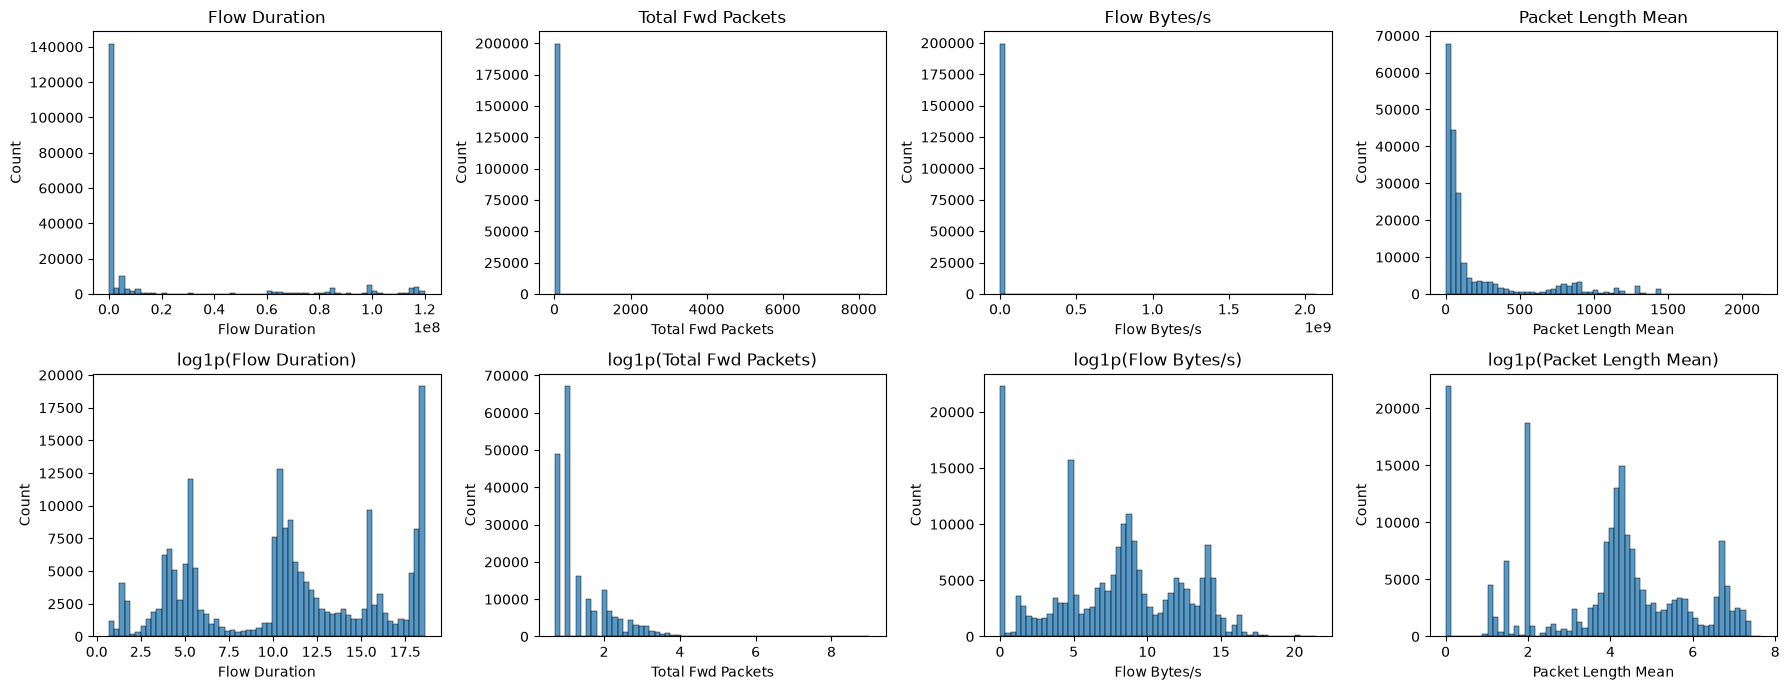

In [17]:
key = ["Flow Duration", "Total Fwd Packets", "Flow Bytes/s", "Packet Length Mean"]
fig, ax = plt.subplots(2, len(key), figsize=(18, 7))
for i, c in enumerate(key):
    s = df[c].sample(200_000, random_state=1)
    sns.histplot(s, bins=60, ax=ax[0, i]).set_title(c)
    sns.histplot(np.log1p(s.clip(lower=0)), bins=60, ax=ax[1, i]).set_title(f"log1p({c})")
plt.tight_layout(); plt.show()

In [18]:
# Outlier Detection
num_cols = df.select_dtypes("number").columns
cont_cols = [c for c in num_cols if df[c].nunique() > 2]  

q = df[cont_cols].quantile([.25, .75])
iqr = q.loc[.75] - q.loc[.25]
lo, hi = q.loc[.25] - 1.5 * iqr, q.loc[.75] + 1.5 * iqr

zero_iqr = iqr[iqr == 0].index.tolist()
usable = iqr[iqr > 0].index.tolist()
print("Skipped (IQR = 0):", zero_iqr)

out = (df[usable] < lo[usable]) | (df[usable] > hi[usable]) 
rate = out.mean().sort_values(ascending=False)
print((rate * 100).round(1).head(15))
print("Median outlier rate across features: {:.1f}%".format(rate.median() * 100))

Skipped (IQR = 0): ['Active Mean', 'Active Std', 'Active Max', 'Active Min', 'Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min']
Bwd Packets/s                  23.4
Fwd IAT Std                    23.4
Total Length of Bwd Packets    22.8
Subflow Bwd Bytes              22.8
Destination Port               21.9
Bwd IAT Total                  21.0
Bwd IAT Mean                   20.7
Fwd IAT Min                    20.5
Bwd IAT Max                    20.3
Fwd IAT Mean                   20.2
Flow IAT Mean                  20.0
Bwd IAT Std                    19.7
Packet Length Variance         19.1
Flow IAT Min                   19.1
Flow Bytes/s                   19.0
dtype: float64
Median outlier rate across features: 13.0%


In [19]:
# Repeating the same for log-scale
slog = lambda s: np.sign(s) * np.log1p(s.abs())
rate_log = {}
for c in usable:
    t = slog(df[c])
    a, b = t.quantile([.25, .75]); r = b - a
    rate_log[c] = ((t < a - 1.5*r) | (t > b + 1.5*r)).mean() if r > 0 else np.nan
cmp = pd.DataFrame({"raw": rate, "log": pd.Series(rate_log)}).sort_values("raw", ascending=False)
print((cmp * 100).round(1).head(15))

                              raw   log
Bwd Packets/s                23.4   0.0
Fwd IAT Std                  23.4   0.0
Subflow Bwd Bytes            22.8   0.0
Total Length of Bwd Packets  22.8   0.0
Destination Port             21.9  16.9
Bwd IAT Total                21.0   0.0
Bwd IAT Mean                 20.7   0.0
Fwd IAT Min                  20.5   7.6
Bwd IAT Max                  20.3   0.0
Fwd IAT Mean                 20.2   0.0
Flow IAT Mean                20.0   0.0
Bwd IAT Std                  19.7   0.0
Packet Length Variance       19.1   0.0
Flow IAT Min                 19.1  15.1
Flow Bytes/s                 19.0   0.0


In [20]:
# 4 groups 
# 1.IQR=0 for Active* and Idle*
# 2.Destination Port
# 3.Flow IAT Min and Fwd IAT Min

# 1.
ai = ["Active Mean", "Active Std", "Active Max", "Active Min",
      "Idle Mean", "Idle Std", "Idle Max", "Idle Min"]
lab = df["Label_grouped"] if "Label_grouped" in df else df["Label"]

print("Share of rows that are 0:\n", (df[ai] == 0).mean().round(3), "\n")
print("Share non-zero, by class:")
display((df[ai] > 0).groupby(lab).mean().round(3))

#2.
port = df["Destination Port"].astype(int)
port_group = pd.cut(port, [-1, 1023, 49151, 65535],
                    labels=["well-known", "registered", "dynamic"])
display(pd.crosstab(port_group, lab, normalize="columns").round(3))

for l in ["BENIGN", "DoS Hulk", "DDoS", "PortScan", "SSH-Patator", "FTP-Patator"]:
    print(l, port[lab == l].value_counts().head(5).to_dict())

# 3.
for c in ["Flow IAT Min", "Fwd IAT Min"]:
    print(f"\n{c}: below lower fence {(df[c] < lo[c]).mean():.1%} | above upper fence {(df[c] > hi[c]).mean():.1%}")
display(out[["Flow IAT Min", "Fwd IAT Min"]].groupby(lab).mean().round(3))

Share of rows that are 0:
 Active Mean    0.777
Active Std     0.918
Active Max     0.777
Active Min     0.777
Idle Mean      0.773
Idle Std       0.909
Idle Max       0.773
Idle Min       0.773
dtype: float64 

Share non-zero, by class:


,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
Label,,,,,,,,
BENIGN,0.172,0.098,0.172,0.172,0.173,0.100,0.173,0.173
Bot,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001
DDoS,0.398,0.000,0.398,0.398,0.399,0.094,0.399,0.399
DoS GoldenEye,0.557,0.006,0.557,0.557,0.818,0.008,0.818,0.818
DoS Hulk,0.794,0.000,0.794,0.794,0.820,0.019,0.820,0.820
DoS Slowhttptest,0.766,0.045,0.766,0.766,0.768,0.578,0.768,0.768
DoS slowloris,0.573,0.333,0.573,0.573,0.573,0.340,0.573,0.573
FTP-Patator,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Heartbleed,0.143,0.000,0.143,0.143,0.143,0.000,0.143,0.143


Label,BENIGN,Bot,DDoS,DoS GoldenEye,DoS Hulk,DoS Slowhttptest,DoS slowloris,FTP-Patator,Heartbleed,Infiltration,PortScan,SSH-Patator,Web Attack - Brute Force,Web Attack - Sql Injection,Web Attack - XSS
Destination Port,,,,,,,,,,,,,,,
well-known,0.774,0.000,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.164,1.0,1.0,1.0,1.0
registered,0.083,0.766,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.782,0.0,0.0,0.0,0.0
dynamic,0.144,0.234,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.054,0.0,0.0,0.0,0.0


BENIGN {53: 859542, 443: 466007, 80: 215685, 123: 20590, 22: 6606}
DoS Hulk {80: 172688}
DDoS {80: 127992, 64869: 1, 64873: 1, 27636: 1}
PortScan {80: 372, 22: 243, 21: 243, 139: 196, 445: 179}
SSH-Patator {22: 3217}
FTP-Patator {21: 5926, 80: 1}

Flow IAT Min: below lower fence 0.0% | above upper fence 19.1%

Fwd IAT Min: below lower fence 0.0% | above upper fence 20.5%


,Flow IAT Min,Fwd IAT Min
Label,,
BENIGN,0.219,0.200
Bot,0.253,0.270
DDoS,0.098,0.310
DoS GoldenEye,0.250,0.593
DoS Hulk,0.017,0.189
DoS Slowhttptest,0.605,0.894
DoS slowloris,0.306,0.884
FTP-Patator,0.002,0.558
Heartbleed,0.000,0.000


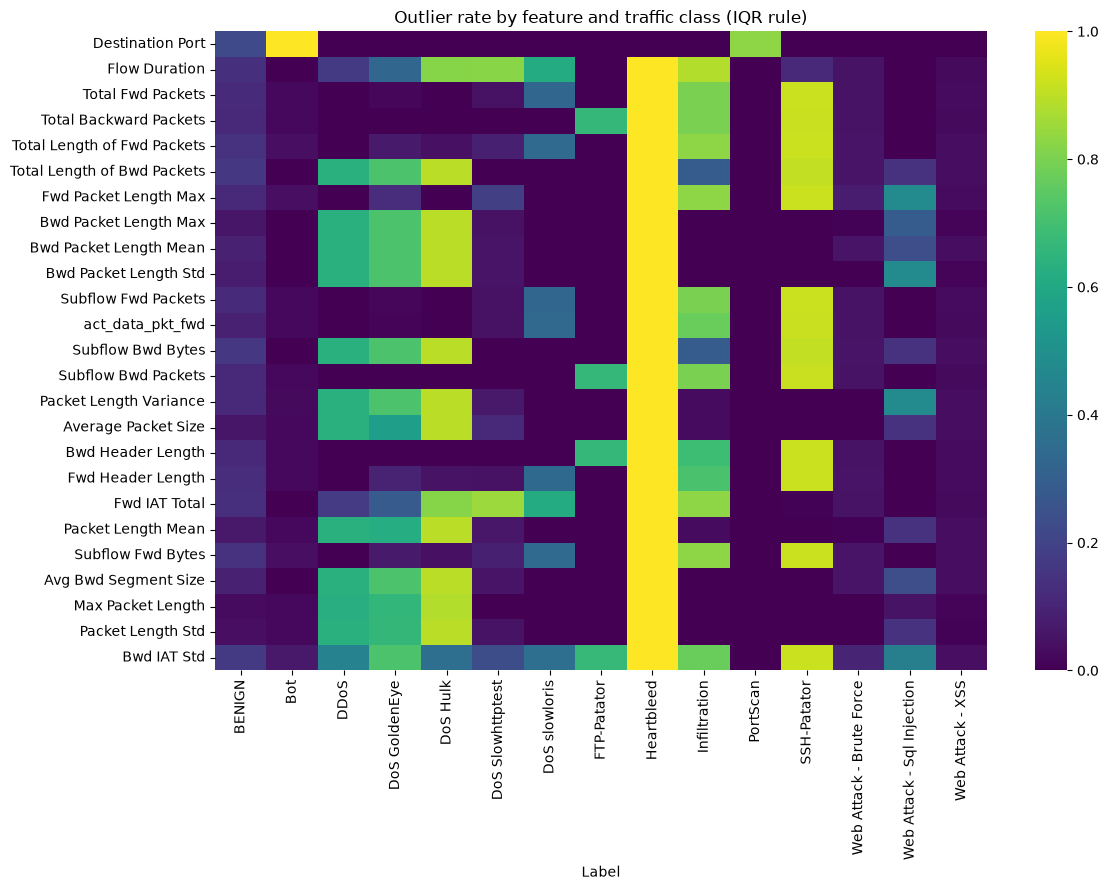

In [21]:
# Do the outliers concentrate in particular classes?

lab = df["Label_grouped"] if "Label_grouped" in df else df["Label"]
y = (df["Label"] != "BENIGN")

rate_by_class = out.groupby(lab).mean().T        

# Show the 25 features whose outlier rate differs most across classes
# Creating a Heatmap for Visual
spread = (rate_by_class.max(axis=1) - rate_by_class.min(axis=1)).sort_values(ascending=False)
plt.figure(figsize=(12, 9))
sns.heatmap(rate_by_class.loc[spread.index[:25]], cmap="viridis", annot=False)
plt.title("Outlier rate by feature and traffic class (IQR rule)")
plt.tight_layout(); plt.show()

In [22]:
# Informative outliers

base = y.mean()
tbl = pd.DataFrame({
    "outlier_rate_%": (out.mean() * 100).round(1),
    "attack_share_among_outliers_%": out.apply(lambda s: y[s].mean() * 100).round(1),
    "rate_in_attacks_%": (out[y].mean() * 100).round(1),
    "rate_in_benign_%": (out[~y].mean() * 100).round(1),
})
tbl["lift"] = (tbl["rate_in_attacks_%"] / tbl["rate_in_benign_%"]).round(2)
print(f"Baseline attack share: {base:.1%}")
display(tbl.sort_values("lift", ascending=False).head(15))
display(tbl.sort_values("lift").head(10))

Baseline attack share: 17.1%


,outlier_rate_%,attack_share_among_outliers_%,rate_in_attacks_%,rate_in_benign_%,lift
Max Packet Length,12.2,79.0,56.5,3.1,18.23
Packet Length Std,13.0,75.2,57.2,3.9,14.67
Bwd Packet Length Max,14.6,67.1,57.3,5.8,9.88
Average Packet Size,14.5,67.0,57.0,5.8,9.83
Packet Length Mean,15.1,64.7,57.1,6.4,8.92
Bwd Packet Length Std,16.0,61.2,57.3,7.5,7.64
Fwd IAT Max,11.9,59.8,41.7,5.8,7.19
Flow IAT Max,11.8,59.1,41.0,5.8,7.07
Bwd Packet Length Mean,17.3,56.6,57.3,9.0,6.37
Avg Bwd Segment Size,17.3,56.6,57.3,9.0,6.37


,outlier_rate_%,attack_share_among_outliers_%,rate_in_attacks_%,rate_in_benign_%,lift
Bwd Packet Length Min,2.6,0.1,0.0,3.2,0.00
min_seg_size_forward,0.1,0.3,0.0,0.1,0.00
Init_Win_bytes_backward,11.4,1.3,0.9,13.5,0.07
Total Fwd Packets,10.1,2.2,1.3,11.9,0.11
Subflow Fwd Packets,10.1,2.2,1.3,11.9,0.11
Fwd Packet Length Max,9.6,2.3,1.3,11.3,0.12
act_data_pkt_fwd,7.7,2.8,1.3,9.0,0.14
Total Backward Packets,9.5,3.0,1.7,11.1,0.15
Bwd Header Length,9.6,3.0,1.7,11.3,0.15
Subflow Bwd Packets,9.5,3.0,1.7,11.1,0.15


In [23]:
# Where are the most extreme values from

for c in ["Subflow Bwd Bytes", "Flow Bytes/s", "Flow Duration", "Total Fwd Packets", "Fwd Header Length"]:
    top = df.nlargest(500, c)
    print(f"\n{c}: top 500 rows by label")
    print(top["Label"].value_counts().head(5).to_dict())
    print(f"  max / 99th percentile = {df[c].max() / df[c].quantile(.99):,.0f}")


Subflow Bwd Bytes: top 500 rows by label
{'BENIGN': 494, 'Heartbleed': 6}
  max / 99th percentile = 5,135

Flow Bytes/s: top 500 rows by label
{'BENIGN': 499, 'DoS Slowhttptest': 1}
  max / 99th percentile = 168

Flow Duration: top 500 rows by label
{'BENIGN': 498, 'Infiltration': 2}
  max / 99th percentile = 1

Total Fwd Packets: top 500 rows by label
{'BENIGN': 485, 'Infiltration': 9, 'Heartbleed': 6}
  max / 99th percentile = 2,243

Fwd Header Length: top 500 rows by label
{'BENIGN': 485, 'Infiltration': 9, 'Heartbleed': 6}
  max / 99th percentile = 1,694


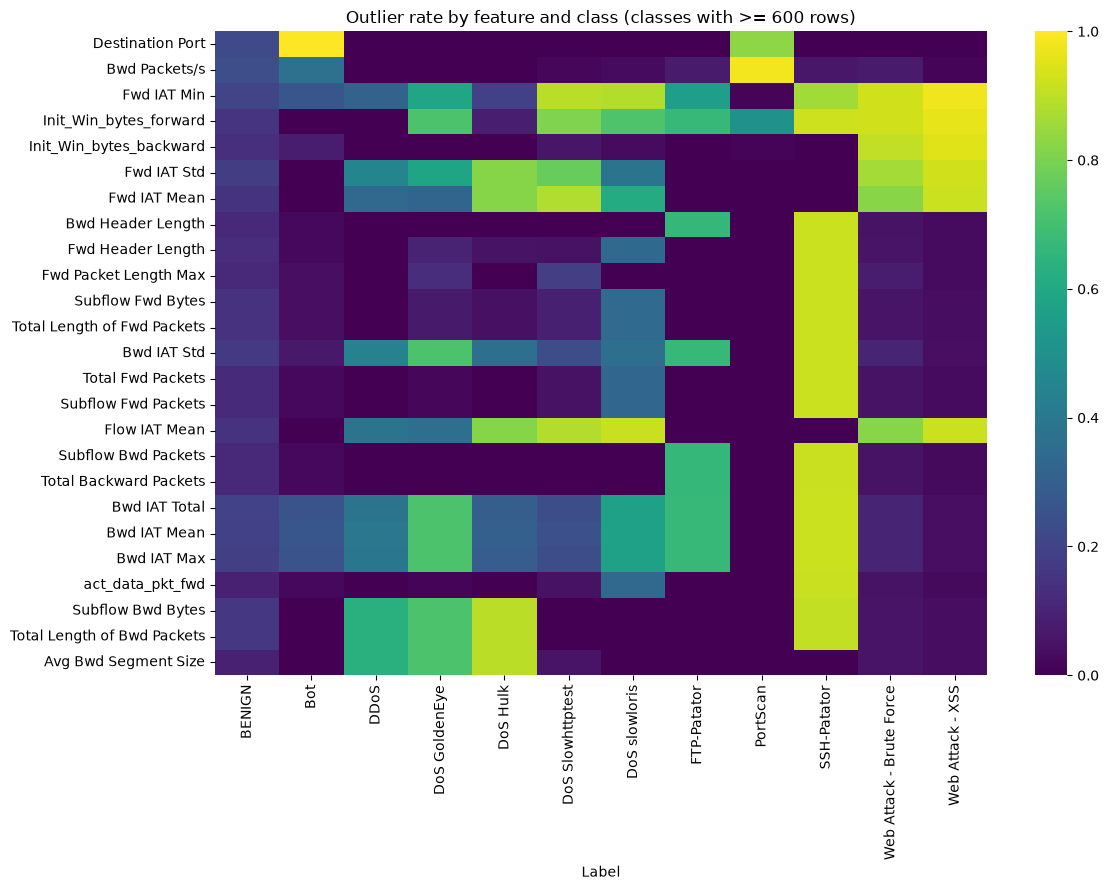

In [24]:
rare = ["Heartbleed", "Infiltration", "Web Attack - Sql Injection"]
keep = ~lab.isin(rare)
rbc = out[keep].groupby(lab[keep]).mean().T
spread = (rbc.max(axis=1) - rbc.min(axis=1)).sort_values(ascending=False)

plt.figure(figsize=(12, 9))
sns.heatmap(rbc.loc[spread.index[:25]], cmap="viridis", vmin=0, vmax=1)
plt.title("Outlier rate by feature and class (classes with >= 600 rows)")
plt.tight_layout(); plt.show()

In [25]:
# Features
from scipy.stats import mannwhitneyu
from sklearn.feature_selection import mutual_info_classif

num_cols = df.select_dtypes("number").columns
feats = [c for c in num_cols if df[c].nunique() > 1 and c != "is_attack"]

# Balanced sample: equal benign and attack rows
y_all = (df["Label"] != "BENIGN")
samp = pd.concat([df[~y_all].sample(30_000, random_state=42),
                  df[y_all].sample(30_000, random_state=42)])
ys = (samp["Label"] != "BENIGN").astype(int)

rows = []
for c in feats:
    a, b = samp.loc[ys == 1, c], samp.loc[ys == 0, c]
    U = mannwhitneyu(a, b)[0]
    auc = U / (len(a) * len(b))
    rows.append((c, auc, abs(2 * auc - 1)))
eff = pd.DataFrame(rows, columns=["feature", "auc", "effect"]).set_index("feature")
eff["mi"] = mutual_info_classif(samp[feats], ys, random_state=42)
eff = eff.sort_values("effect", ascending=False)
display(eff.head(15)); display(eff.tail(10))

,auc,effect,mi
feature,,,
Fwd IAT Std,0.747277,0.494555,0.246284
Bwd Packet Length Std,0.743858,0.487715,0.317504
Min Packet Length,0.271982,0.456036,0.192583
Fwd Packet Length Min,0.274282,0.451435,0.192363
Flow IAT Std,0.711804,0.423607,0.239759
Bwd Packet Length Min,0.290332,0.419335,0.190460
Fwd IAT Max,0.704413,0.408827,0.352959
Fwd IAT Mean,0.698345,0.396690,0.317618
Flow IAT Max,0.691439,0.382879,0.329529


,auc,effect,mi
feature,,,
Down/Up Ratio,0.471629,0.056741,0.025898
Destination Port,0.524731,0.049461,0.472065
SYN Flag Count,0.476683,0.046633,0.008273
Fwd PSH Flags,0.476683,0.046633,0.008679
Idle Std,0.476757,0.046486,0.044387
min_seg_size_forward,0.505049,0.010097,0.048759
ECE Flag Count,0.499817,0.000367,0.000000
RST Flag Count,0.499817,0.000367,0.000000
Fwd URG Flags,0.499967,0.000067,0.002234


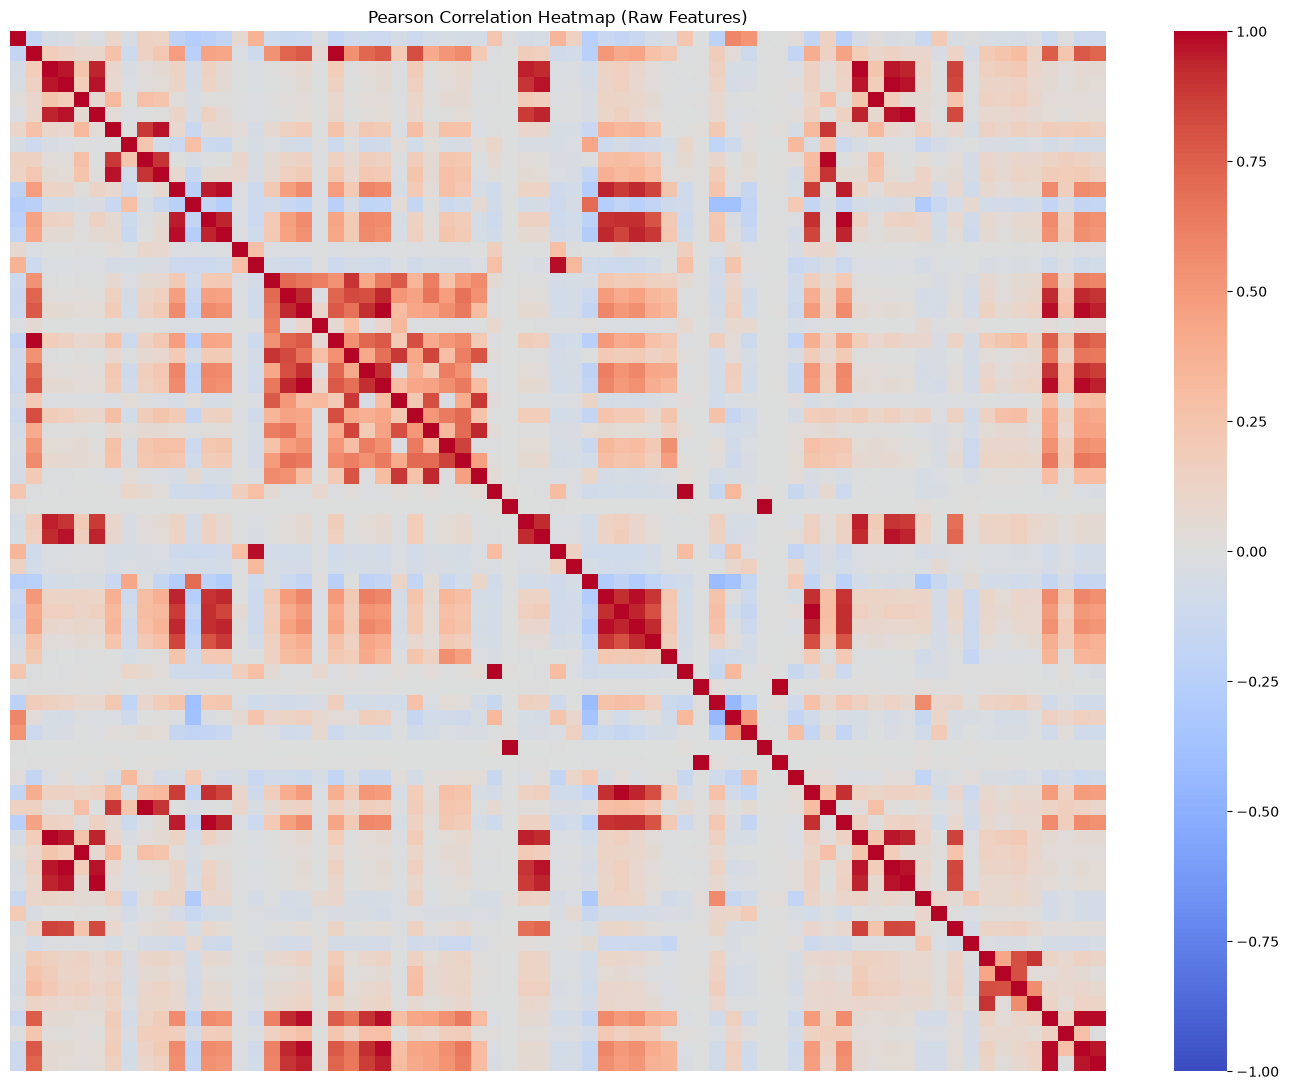

,Feature 1,Feature 2,Correlation,Absolute Correlation
191,Total Fwd Packets,Subflow Fwd Packets,1.000000,1.000000
880,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000,1.000000
330,Total Length of Fwd Packets,Subflow Fwd Bytes,1.000000,1.000000
262,Total Backward Packets,Subflow Bwd Packets,1.000000,1.000000
2112,Fwd PSH Flags,SYN Flag Count,1.000000,1.000000
3015,RST Flag Count,ECE Flag Count,1.000000,1.000000
2186,Fwd URG Flags,CWE Flag Count,1.000000,1.000000
603,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000,1.000000
401,Total Length of Bwd Packets,Subflow Bwd Bytes,1.000000,1.000000
89,Flow Duration,Fwd IAT Total,0.998580,0.998580


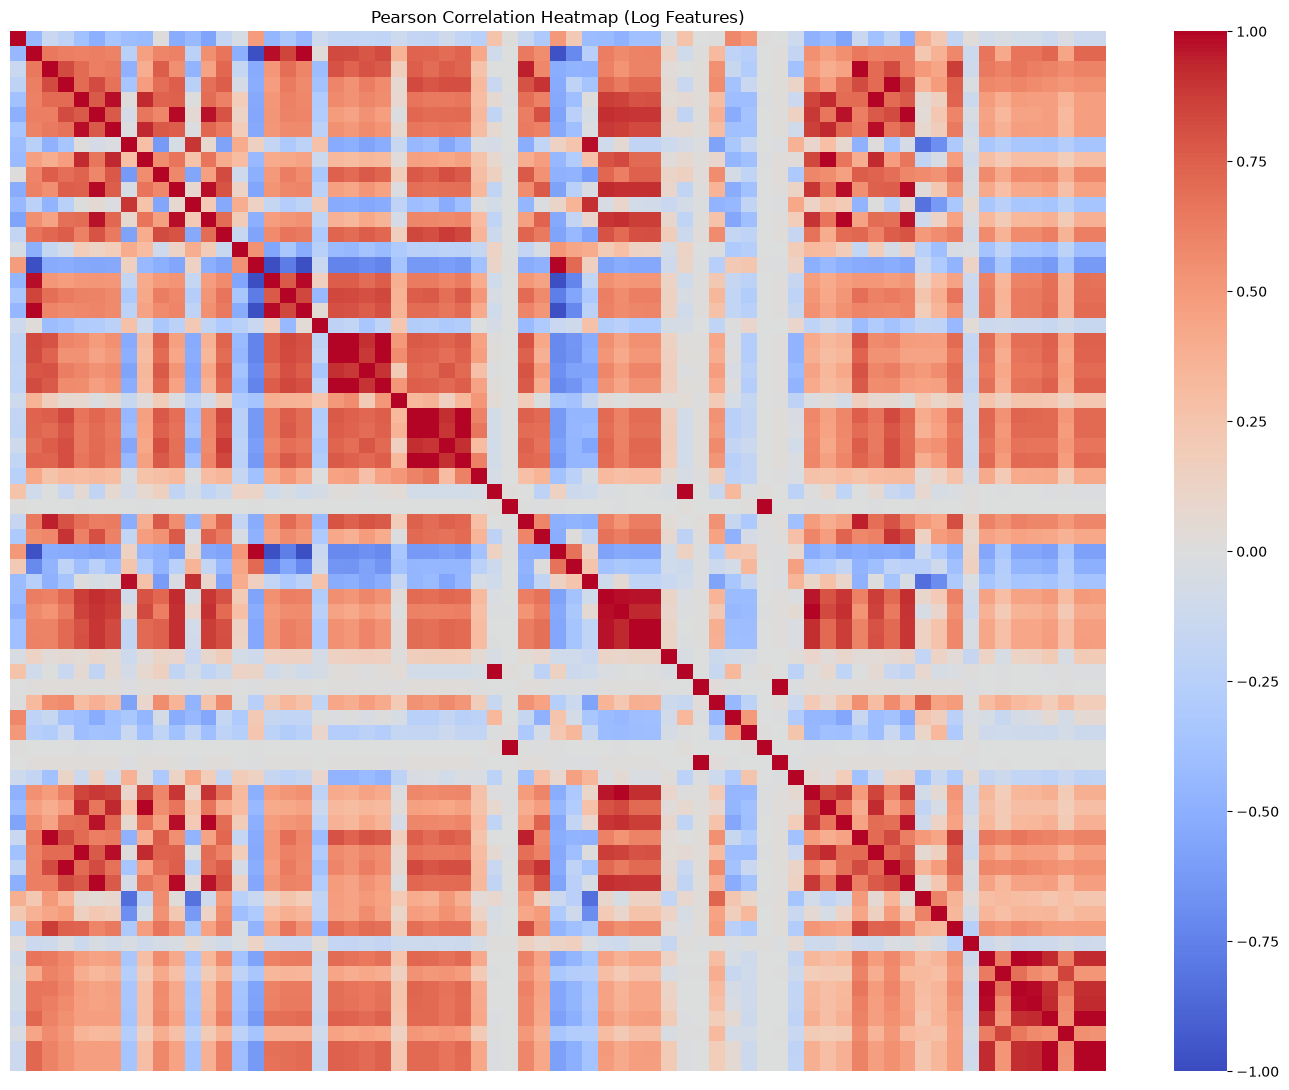

,Feature 1,Feature 2,Correlation,Absolute Correlation
262,Total Backward Packets,Subflow Bwd Packets,1.000000,1.000000
330,Total Length of Fwd Packets,Subflow Fwd Bytes,1.000000,1.000000
191,Total Fwd Packets,Subflow Fwd Packets,1.000000,1.000000
603,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000,1.000000
2112,Fwd PSH Flags,SYN Flag Count,1.000000,1.000000
2186,Fwd URG Flags,CWE Flag Count,1.000000,1.000000
3015,RST Flag Count,ECE Flag Count,1.000000,1.000000
880,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000,1.000000
401,Total Length of Bwd Packets,Subflow Bwd Bytes,1.000000,1.000000
4552,Idle Mean,Idle Max,0.999953,0.999953


In [26]:
# Correlation analysis using a sample
SEED = 42
CORR_SAMPLE = 200_000
CORR_THRESHOLD = 0.95

feats = [c for c in num_cols if df[c].nunique() > 1]

samp_corr = df[feats].sample(
    min(CORR_SAMPLE, len(df)),
    random_state=SEED
)

slog = lambda s: np.sign(s) * np.log1p(np.abs(s))

# Raw and log-transformed correlation
for name, X in [
    ("Raw", samp_corr),
    ("Log", slog(samp_corr))
]:
    C = X.corr(method="pearson")

    plt.figure(figsize=(14, 11))
    sns.heatmap(
        C,
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        xticklabels=False,
        yticklabels=False
    )
    plt.title(f"Pearson Correlation Heatmap ({name} Features)")
    plt.tight_layout()
    plt.show()

    U = C.where(np.triu(np.ones(C.shape, dtype=bool), 1))

    pairs = (
        U.stack()
        .rename("correlation")
        .reset_index()
    )

    pairs.columns = ["Feature 1", "Feature 2", "Correlation"]

    high = pairs[
        pairs["Correlation"].abs() > CORR_THRESHOLD
    ].copy()

    high["Absolute Correlation"] = high["Correlation"].abs()

    display(
        high.sort_values(
            "Absolute Correlation",
            ascending=False
        ).head(20)
    )

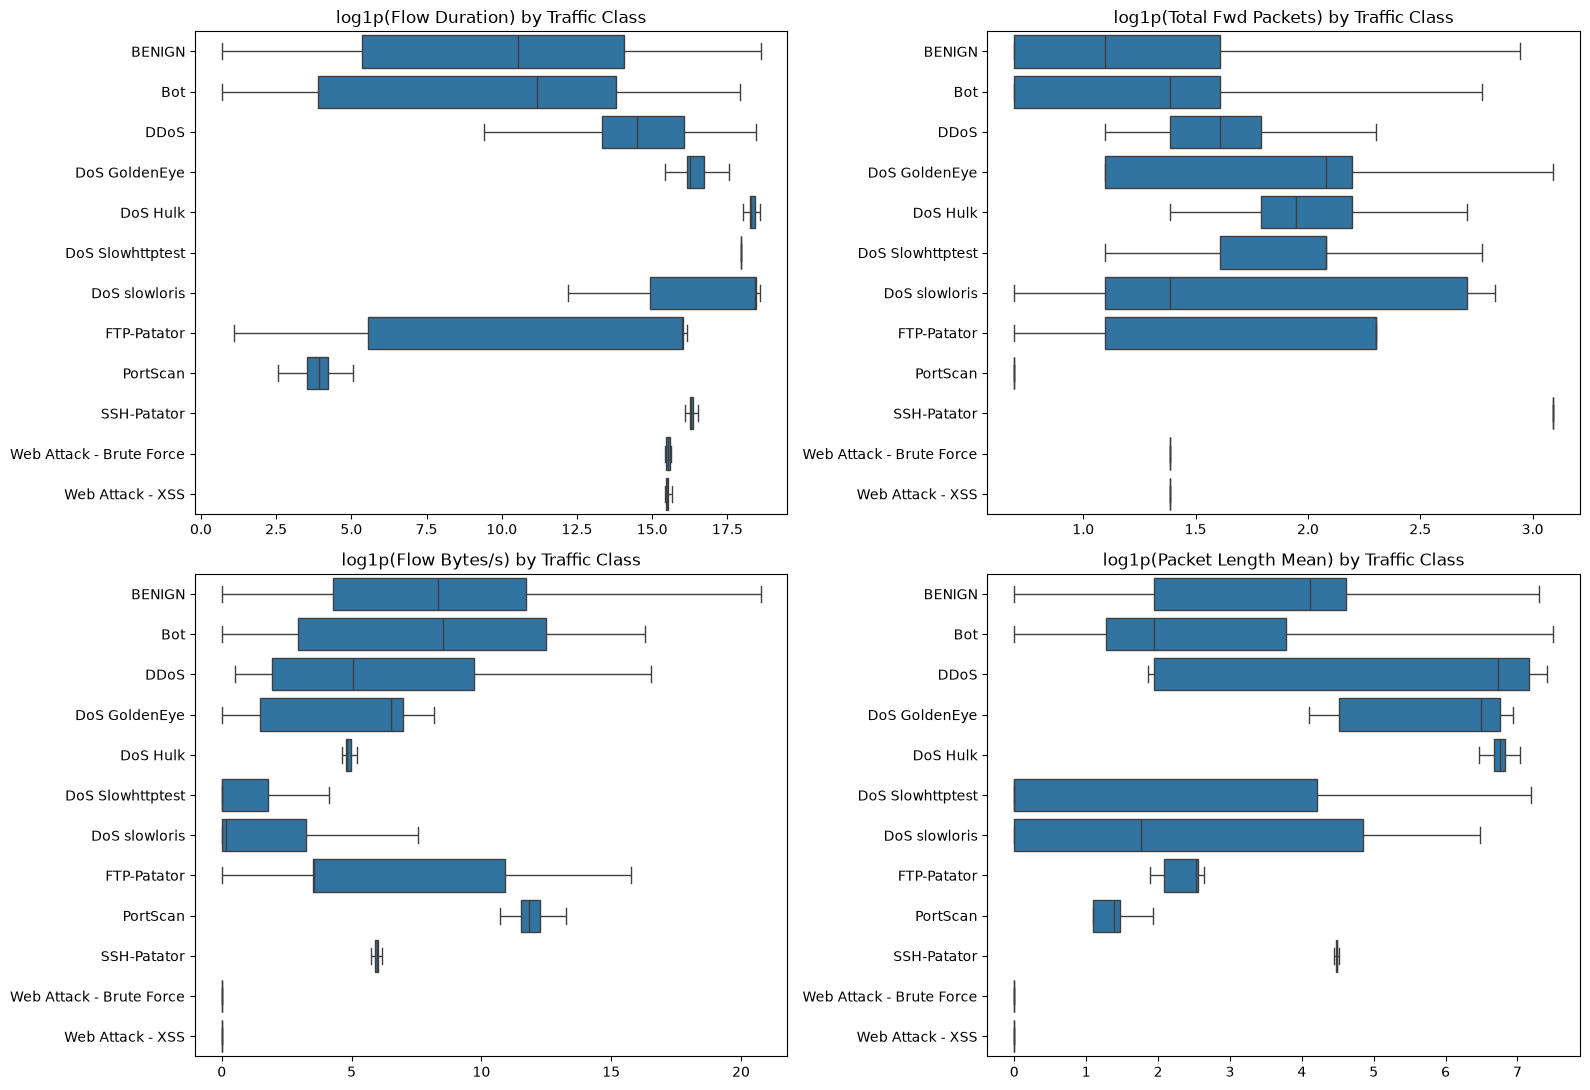

,Flow Duration,Total Fwd Packets,Flow Bytes/s,Packet Length Mean
Label,,,,
BENIGN,4.610600e+04,2.0,4145.680176,61.599998
Bot,7.103550e+04,3.0,5013.129883,6.000000
DDoS,1.879086e+06,4.0,160.100006,833.500000
DoS GoldenEye,1.158732e+07,7.0,650.669983,461.329987
DoS Hulk,8.640240e+07,6.0,123.849998,852.570007
DoS Slowhttptest,6.312044e+07,7.0,0.000000,0.000000
DoS slowloris,9.999941e+07,3.0,0.160000,4.800000
FTP-Patator,8.686554e+06,9.0,33.910000,11.600000
Heartbleed,1.192611e+08,2782.0,66172.437500,1620.050049


In [27]:
# Feature-wise comparison across traffic classes

lab = df["Label"]

MIN_CLASS_ROWS = 600

keep_classes = lab.value_counts()[
    lab.value_counts() >= MIN_CLASS_ROWS
].index

sub = df[lab.isin(keep_classes)].copy()

sub = pd.concat([
    group.sample(min(len(group), 3000), random_state=42)
    for _, group in sub.groupby("Label")
])

key_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Flow Bytes/s",
    "Packet Length Mean"
]

key_features = [c for c in key_features if c in df.columns]

fig, ax = plt.subplots(2, 2, figsize=(16, 11))

for a, c in zip(ax.ravel(), key_features):
    sns.boxplot(
        data=sub.assign(
            transformed=np.log1p(sub[c].clip(lower=0))
        ),
        x="transformed",
        y="Label",
        showfliers=False,
        ax=a
    )

    a.set_title(f"log1p({c}) by Traffic Class")
    a.set_xlabel("")
    a.set_ylabel("")

plt.tight_layout()
plt.show()

# Class-wise median values
class_medians = df.groupby("Label")[key_features].median().round(2)

display(class_medians)

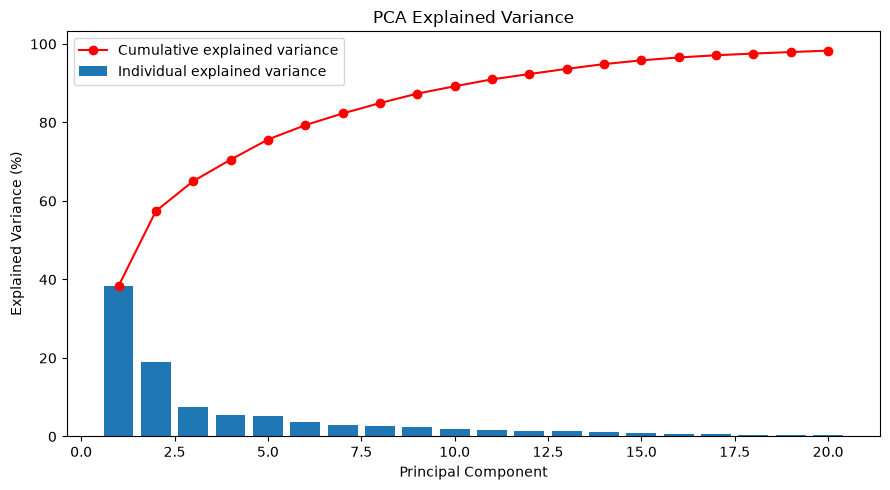

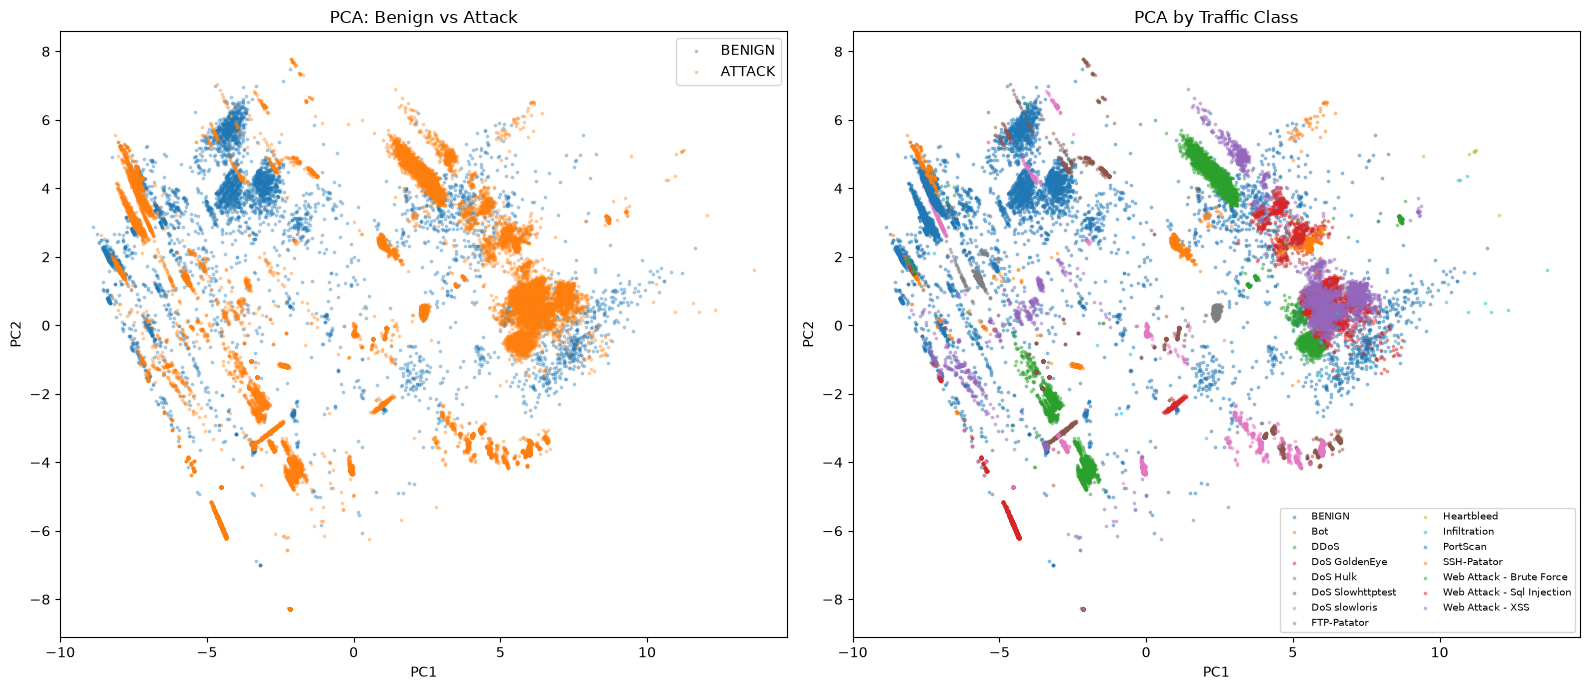

PC1 variance: 38.33 %
PC2 variance: 19.09 %
Cumulative variance (first 10 PCs): 89.22 %


In [28]:
# Stratified sampling for PCA
PCA_PER_CLASS = 5000

samp_pca = pd.concat([
    group.sample(min(len(group), PCA_PER_CLASS), random_state=42)
    for _, group in df.groupby("Label")
])

pca_features = [
    c for c in num_cols
    if c in samp_pca.columns and samp_pca[c].nunique() > 1
]

X = slog(samp_pca[pca_features])

# Standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA
pca = PCA(
    n_components=min(20, len(pca_features)),
    random_state=42
)

Z = pca.fit_transform(X_scaled)

# Explained variance
ev = pca.explained_variance_ratio_
cum_ev = np.cumsum(ev)

plt.figure(figsize=(9, 5))

plt.bar(
    range(1, len(ev) + 1),
    ev * 100,
    label="Individual explained variance"
)

plt.plot(
    range(1, len(ev) + 1),
    cum_ev * 100,
    "ro-",
    label="Cumulative explained variance"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("PCA Explained Variance")
plt.legend()
plt.tight_layout()
plt.show()

# PCA scatter plots
yb = (samp_pca["Label"] != "BENIGN").values

fig, ax = plt.subplots(1, 2, figsize=(16, 7))

ax[0].scatter(
    Z[~yb, 0], Z[~yb, 1],
    s=3, alpha=0.3, label="BENIGN"
)

ax[0].scatter(
    Z[yb, 0], Z[yb, 1],
    s=3, alpha=0.3, label="ATTACK"
)

ax[0].set_title("PCA: Benign vs Attack")
ax[0].set_xlabel("PC1")
ax[0].set_ylabel("PC2")
ax[0].legend()

for label in sorted(samp_pca["Label"].unique()):
    mask = (samp_pca["Label"] == label).values

    ax[1].scatter(
        Z[mask, 0],
        Z[mask, 1],
        s=3,
        alpha=0.4,
        label=label
    )

ax[1].set_title("PCA by Traffic Class")
ax[1].set_xlabel("PC1")
ax[1].set_ylabel("PC2")
ax[1].legend(fontsize=7, ncol=2)

plt.tight_layout()
plt.show()

print("PC1 variance:", round(ev[0] * 100, 2), "%")
print("PC2 variance:", round(ev[1] * 100, 2), "%")
print("Cumulative variance (first 10 PCs):",
      round(cum_ev[min(9, len(cum_ev)-1)] * 100, 2), "%")

In [29]:
# Feature selection
feats = [
    c for c in num_cols
    if df[c].nunique() > 1 and c != "is_attack"
]

yb = (df["Label"] != "BENIGN")

# Variance analysis
vt_sample = df[feats].sample(
    min(300_000, len(df)),
    random_state=42
)

vt = VarianceThreshold(threshold=0.0)
vt.fit(vt_sample)

zero_var = [
    f for f, keep in zip(feats, vt.get_support())
    if not keep
]

# Near-constant features
near_const = []

for c in feats:
    dominant_share = df[c].value_counts(normalize=True).iloc[0]

    if dominant_share > 0.999:
        near_const.append(c)

print("Zero variance features:", zero_var)
print("Near-constant features:", near_const)

# Balanced sample: equal benign and attack observations
BAL_N = min(30_000, int(yb.sum()), int((~yb).sum()))

bal = pd.concat([
    df[~yb].sample(BAL_N, random_state=42),
    df[yb].sample(BAL_N, random_state=42)
])

yy = (bal["Label"] != "BENIGN").astype(int)

# Mann-Whitney U test and effect size
from scipy.stats import mannwhitneyu

rows = []

for c in feats:
    a = bal.loc[yy == 1, c]
    b = bal.loc[yy == 0, c]

    U = mannwhitneyu(a, b, alternative="two-sided").statistic

    auc = U / (len(a) * len(b))

    effect = abs(2 * auc - 1)

    rows.append((c, auc, effect))

eff = pd.DataFrame(
    rows,
    columns=["feature", "auc", "effect"]
).set_index("feature")

# Mutual Information
eff["mutual_info"] = mutual_info_classif(
    bal[feats],
    yy,
    random_state=42
)

display(eff.sort_values("effect", ascending=False).head(20))

Zero variance features: []
Near-constant features: ['Fwd URG Flags', 'RST Flag Count', 'CWE Flag Count', 'ECE Flag Count']


,auc,effect,mutual_info
feature,,,
Fwd IAT Std,0.747277,0.494555,0.246284
Bwd Packet Length Std,0.743858,0.487715,0.317504
Min Packet Length,0.271982,0.456036,0.192583
Fwd Packet Length Min,0.274282,0.451435,0.192363
Flow IAT Std,0.711804,0.423607,0.239759
Bwd Packet Length Min,0.290332,0.419335,0.190460
Fwd IAT Max,0.704413,0.408827,0.352959
Fwd IAT Mean,0.698345,0.396690,0.317618
Flow IAT Max,0.691439,0.382879,0.329529


In [30]:
# Stratified class-wise sampling
RF_PER_CLASS = 10_000

rf_sample = pd.concat([
    group.sample(min(len(group), RF_PER_CLASS), random_state=42)
    for _, group in df.groupby("Label")
])

# Remove classes with fewer than 10 observations
class_counts = rf_sample["Label"].value_counts()

rf_sample = rf_sample[
    rf_sample["Label"].isin(
        class_counts[class_counts >= 10].index
    )
]

X_rf = rf_sample[feats]
y_rf = rf_sample["Label"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X_rf,
    y_rf,
    test_size=0.30,
    stratify=y_rf,
    random_state=42
)

# Random Forest classifier
rf = RandomForestClassifier(
    n_estimators=100,
    n_jobs=-1,
    random_state=42,
    class_weight="balanced_subsample"
)

rf.fit(X_train, y_train)

pred = rf.predict(X_test)

# Classification performance
print(classification_report(
    y_test,
    pred,
    zero_division=0
))

print("Accuracy:", round((pred == y_test).mean(), 4))

print(
    "Macro F1:",
    round(f1_score(y_test, pred, average="macro"), 4)
)

# Feature importance
eff["rf_importance"] = pd.Series(
    rf.feature_importances_,
    index=feats
)

# Combined ranking
eff["rank_effect"] = eff["effect"].rank(ascending=False)
eff["rank_mi"] = eff["mutual_info"].rank(ascending=False)
eff["rank_rf"] = eff["rf_importance"].rank(ascending=False)

eff["mean_rank"] = eff[
    ["rank_effect", "rank_mi", "rank_rf"]
].mean(axis=1)

eff["near_constant"] = eff.index.isin(
    near_const + zero_var
)

eff = eff.sort_values("mean_rank")

display(eff.head(25))

                            precision    recall  f1-score   support

                    BENIGN       0.99      0.99      0.99      3000
                       Bot       0.99      0.99      0.99       584
                      DDoS       1.00      1.00      1.00      3000
             DoS GoldenEye       1.00      1.00      1.00      3000
                  DoS Hulk       1.00      1.00      1.00      3000
          DoS Slowhttptest       1.00      0.99      1.00      1569
             DoS slowloris       1.00      1.00      1.00      1612
               FTP-Patator       1.00      1.00      1.00      1778
              Infiltration       1.00      0.82      0.90        11
                  PortScan       1.00      1.00      1.00      3000
               SSH-Patator       1.00      1.00      1.00       965
  Web Attack - Brute Force       0.73      0.79      0.76       441
Web Attack - Sql Injection       1.00      0.50      0.67         6
          Web Attack - XSS       0.43      0.35

,auc,effect,mutual_info,rf_importance,rank_effect,rank_mi,rank_rf,mean_rank,near_constant
feature,,,,,,,,,
Fwd IAT Max,0.704413,0.408827,0.352959,0.025852,7.0,17.0,7.0,10.333333,False
Flow IAT Max,0.691439,0.382879,0.329529,0.022748,9.0,19.0,9.0,12.333333,False
Fwd IAT Mean,0.698345,0.396690,0.317618,0.021643,8.0,20.0,12.0,13.333333,False
Packet Length Variance,0.675856,0.351711,0.508573,0.018852,17.5,3.0,20.0,13.500000,False
Fwd IAT Total,0.679239,0.358477,0.338967,0.021550,16.0,18.0,13.0,15.666667,False
Max Packet Length,0.664214,0.328429,0.458192,0.020228,23.0,8.0,18.0,16.333333,False
Init_Win_bytes_backward,0.631196,0.262391,0.407638,0.053369,31.0,16.0,2.0,16.333333,False
Flow Packets/s,0.316344,0.367311,0.275274,0.027018,15.0,30.0,5.0,16.666667,False
Packet Length Mean,0.648444,0.296888,0.488391,0.018692,26.0,4.0,21.0,17.000000,False


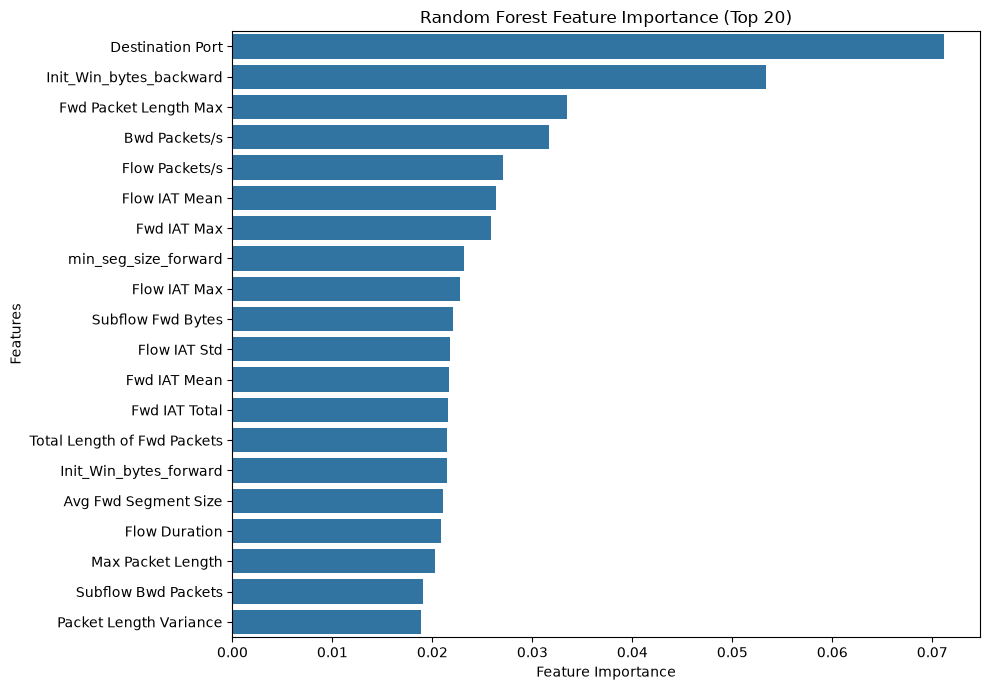

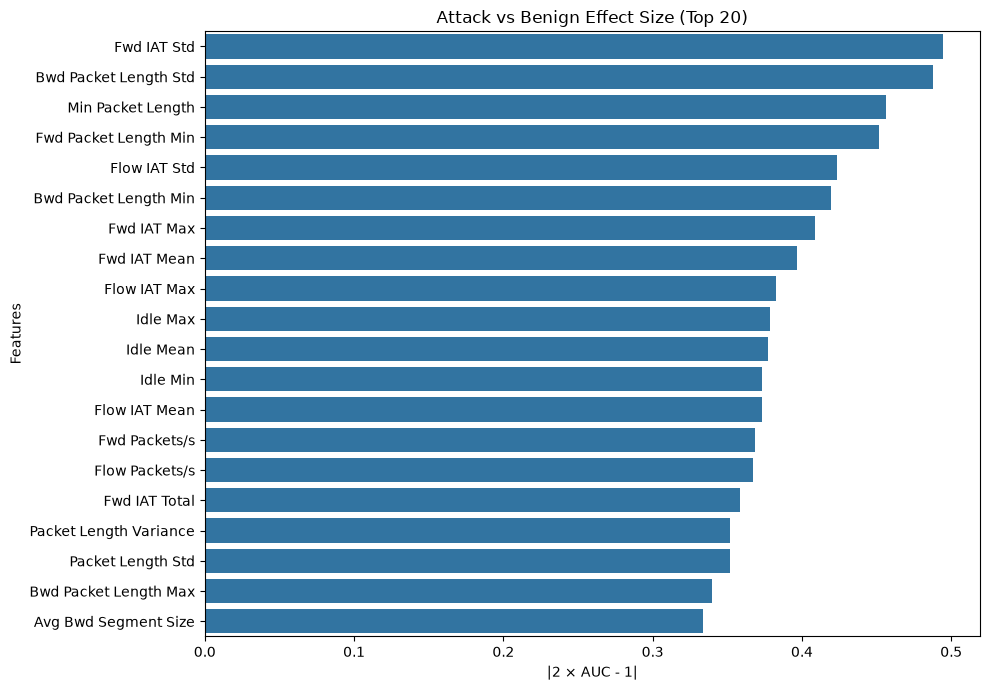

,auc,effect,mutual_info,rf_importance,rank_effect,rank_mi,rank_rf,mean_rank,near_constant
feature,,,,,,,,,
Fwd IAT Max,0.704413,0.408827,0.352959,0.025852,7.0,17.0,7.0,10.333333,False
Flow IAT Max,0.691439,0.382879,0.329529,0.022748,9.0,19.0,9.0,12.333333,False
Fwd IAT Mean,0.698345,0.396690,0.317618,0.021643,8.0,20.0,12.0,13.333333,False
Packet Length Variance,0.675856,0.351711,0.508573,0.018852,17.5,3.0,20.0,13.500000,False
Fwd IAT Total,0.679239,0.358477,0.338967,0.021550,16.0,18.0,13.0,15.666667,False
Max Packet Length,0.664214,0.328429,0.458192,0.020228,23.0,8.0,18.0,16.333333,False
Init_Win_bytes_backward,0.631196,0.262391,0.407638,0.053369,31.0,16.0,2.0,16.333333,False
Flow Packets/s,0.316344,0.367311,0.275274,0.027018,15.0,30.0,5.0,16.666667,False
Packet Length Mean,0.648444,0.296888,0.488391,0.018692,26.0,4.0,21.0,17.000000,False


In [31]:
# Random Forest importance: Top 20 features

top_rf = eff.sort_values(
    "rf_importance",
    ascending=False
).head(20)

plt.figure(figsize=(10, 7))

sns.barplot(
    x=top_rf["rf_importance"],
    y=top_rf.index
)

plt.title("Random Forest Feature Importance (Top 20)")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


# Effect size: Top 20 features

top_effect = eff.sort_values(
    "effect",
    ascending=False
).head(20)

plt.figure(figsize=(10, 7))

sns.barplot(
    x=top_effect["effect"],
    y=top_effect.index
)

plt.title("Attack vs Benign Effect Size (Top 20)")
plt.xlabel("|2 × AUC - 1|")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


# Recommended features after excluding near-constant features

recommended = eff[
    ~eff["near_constant"]
].sort_values("mean_rank")

display(recommended.head(25))

In [32]:
# Data Validation and features

# imports and dataset validation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

df = pd.read_parquet("cic_ids2017_clean.parquet")
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isna().sum().sum())

print("\nInfinite values:")
num_cols = df.select_dtypes(include=np.number).columns
print(np.isinf(df[num_cols]).sum().sum())

print("\nDuplicate observations:")
print(df.drop(columns="session").duplicated().sum())

print("\nClass distribution:")
display(df["Label"].value_counts().to_frame("Count"))

assert "Label" in df.columns
assert "session" in df.columns

Dataset shape: (2495065, 71)

Missing values:
0

Infinite values:
0

Duplicate observations:
0

Class distribution:


,Count
Label,
BENIGN,2069532
DoS Hulk,172688
DDoS,127995
PortScan,90694
DoS GoldenEye,10277
FTP-Patator,5927
DoS slowloris,5374
DoS Slowhttptest,5228
SSH-Patator,3217


In [33]:
# TCP sentinel values
tcp_cols = [
    "Init_Win_bytes_forward",
    "Init_Win_bytes_backward"
]

for col in tcp_cols:
    print(f"\n{col}")
    print(df[col].value_counts().head(10))
    print("Number of -1 values:", (df[col] == -1).sum())


Init_Win_bytes_forward
Init_Win_bytes_forward
-1.0        892898
 8192.0     321746
 29200.0    281808
 256.0       88830
 1024.0      83793
 0.0         80318
 65535.0     70592
 251.0       60117
 274.0       43337
 229.0       35653
Name: count, dtype: int64
Number of -1 values: 892898

Init_Win_bytes_backward
Init_Win_bytes_backward
-1.0        1194059
 0.0         201603
 235.0       176865
 229.0       103701
 256.0        42514
 31.0         18636
 33304.0      18309
 60.0         17671
 29200.0      16012
 65535.0      15000
Name: count, dtype: int64
Number of -1 values: 1194059


In [34]:
# Creating binary indicators for unknown TCP window values
# Creating binary indicators for unknown TCP window values
for col in tcp_cols:
    side = col.replace("Init_Win_bytes_", "")            # 'forward' / 'backward'

    df[f"{side}_unknown"] = (df[col] == -1).astype("int8")   # flag FIRST
    df[col] = df[col].replace(-1, np.nan)                    # THEN replace

print(df[["forward_unknown", "backward_unknown"]].sum())
assert (df[["forward_unknown", "backward_unknown"]].sum() > 0).all()

forward_unknown      892898
backward_unknown    1194059
dtype: int64


In [35]:
# Creating Active/ idle zero indicators

active_idle_cols = [
    "Active Mean",
    "Active Std",
    "Active Max",
    "Active Min",
    "Idle Mean",
    "Idle Std",
    "Idle Max",
    "Idle Min"
]

for col in active_idle_cols:

    if col in df.columns:

        indicator = (
            col.lower()
            .replace(" ", "_")
        )

        df[f"{indicator}_present"] = (
            df[col] > 0
        ).astype("int8")

In [36]:
# Creating Destination Port service categories

def classify_port(port):

    if pd.isna(port):
        return "Unknown"

    port = int(port)

    common_ports = {
        20: "FTP",
        21: "FTP",
        22: "SSH",
        23: "Telnet",
        25: "SMTP",
        53: "DNS",
        67: "DHCP",
        68: "DHCP",
        80: "HTTP",
        110: "POP3",
        123: "NTP",
        143: "IMAP",
        443: "HTTPS",
        445: "SMB",
        993: "IMAPS",
        995: "POP3S"
    }

    if port in common_ports:
        return common_ports[port]

    elif 0 <= port <= 1023:
        return "Other_Well_Known"

    elif 1024 <= port <= 49151:
        return "Registered"

    elif 49152 <= port <= 65535:
        return "Dynamic"

    else:
        return "Unknown"


df["Destination_Port_Group"] = (
    df["Destination Port"].apply(classify_port)
)

display(
    df["Destination_Port_Group"]
    .value_counts()
    .to_frame("Count")
)

,Count
Destination_Port_Group,
DNS,859643
HTTP,539760
HTTPS,466153
Dynamic,302474
Registered,243584
Other_Well_Known,40231
NTP,20591
SSH,10066
FTP,9614


In [37]:
# Examining these features
engineered_cols = [
    "forward_unknown",
    "backward_unknown",
    "active_mean_present",
    "active_std_present",
    "idle_mean_present",
    "idle_std_present",
    "Destination_Port_Group"
]

engineered_cols = [
    c for c in engineered_cols
    if c in df.columns
]

display(df[engineered_cols].head())

print("\nDataset shape after feature engineering:")
print(df.shape)

,forward_unknown,backward_unknown,active_mean_present,active_std_present,idle_mean_present,idle_std_present,Destination_Port_Group
0,0,1,0,0,0,0,Dynamic
1,0,0,0,0,0,0,Dynamic
2,0,0,0,0,0,0,Dynamic
3,0,0,0,0,0,0,Registered
4,0,1,0,0,0,0,Dynamic



Dataset shape after feature engineering:
(2495065, 82)


In [38]:
df.to_parquet(
    "cic_ids2017_engineered.parquet",
    index=False
)

print("Engineered dataset saved successfully.")

Engineered dataset saved successfully.


In [39]:
# Spearman correlation and VIF-based feature reduction
# the correlation Analysis id extended using Spearman correlation and Variance Inflation Factor
# We will Separate training and test data
# Calculate Spearman correlation using training observations
# identify highly correlated feature pairs
# Remove rebundant features
# Calculate VIF on the reduced feature set

# Creating binary label and split the data
df["is_attack"] = (
    df["Label"] != "BENIGN"
).astype("int8")

df_train, df_test = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["is_attack"]
)

print("Training shape:", df_train.shape)
print("Testing shape:", df_test.shape)

Training shape: (1996052, 83)
Testing shape: (499013, 83)


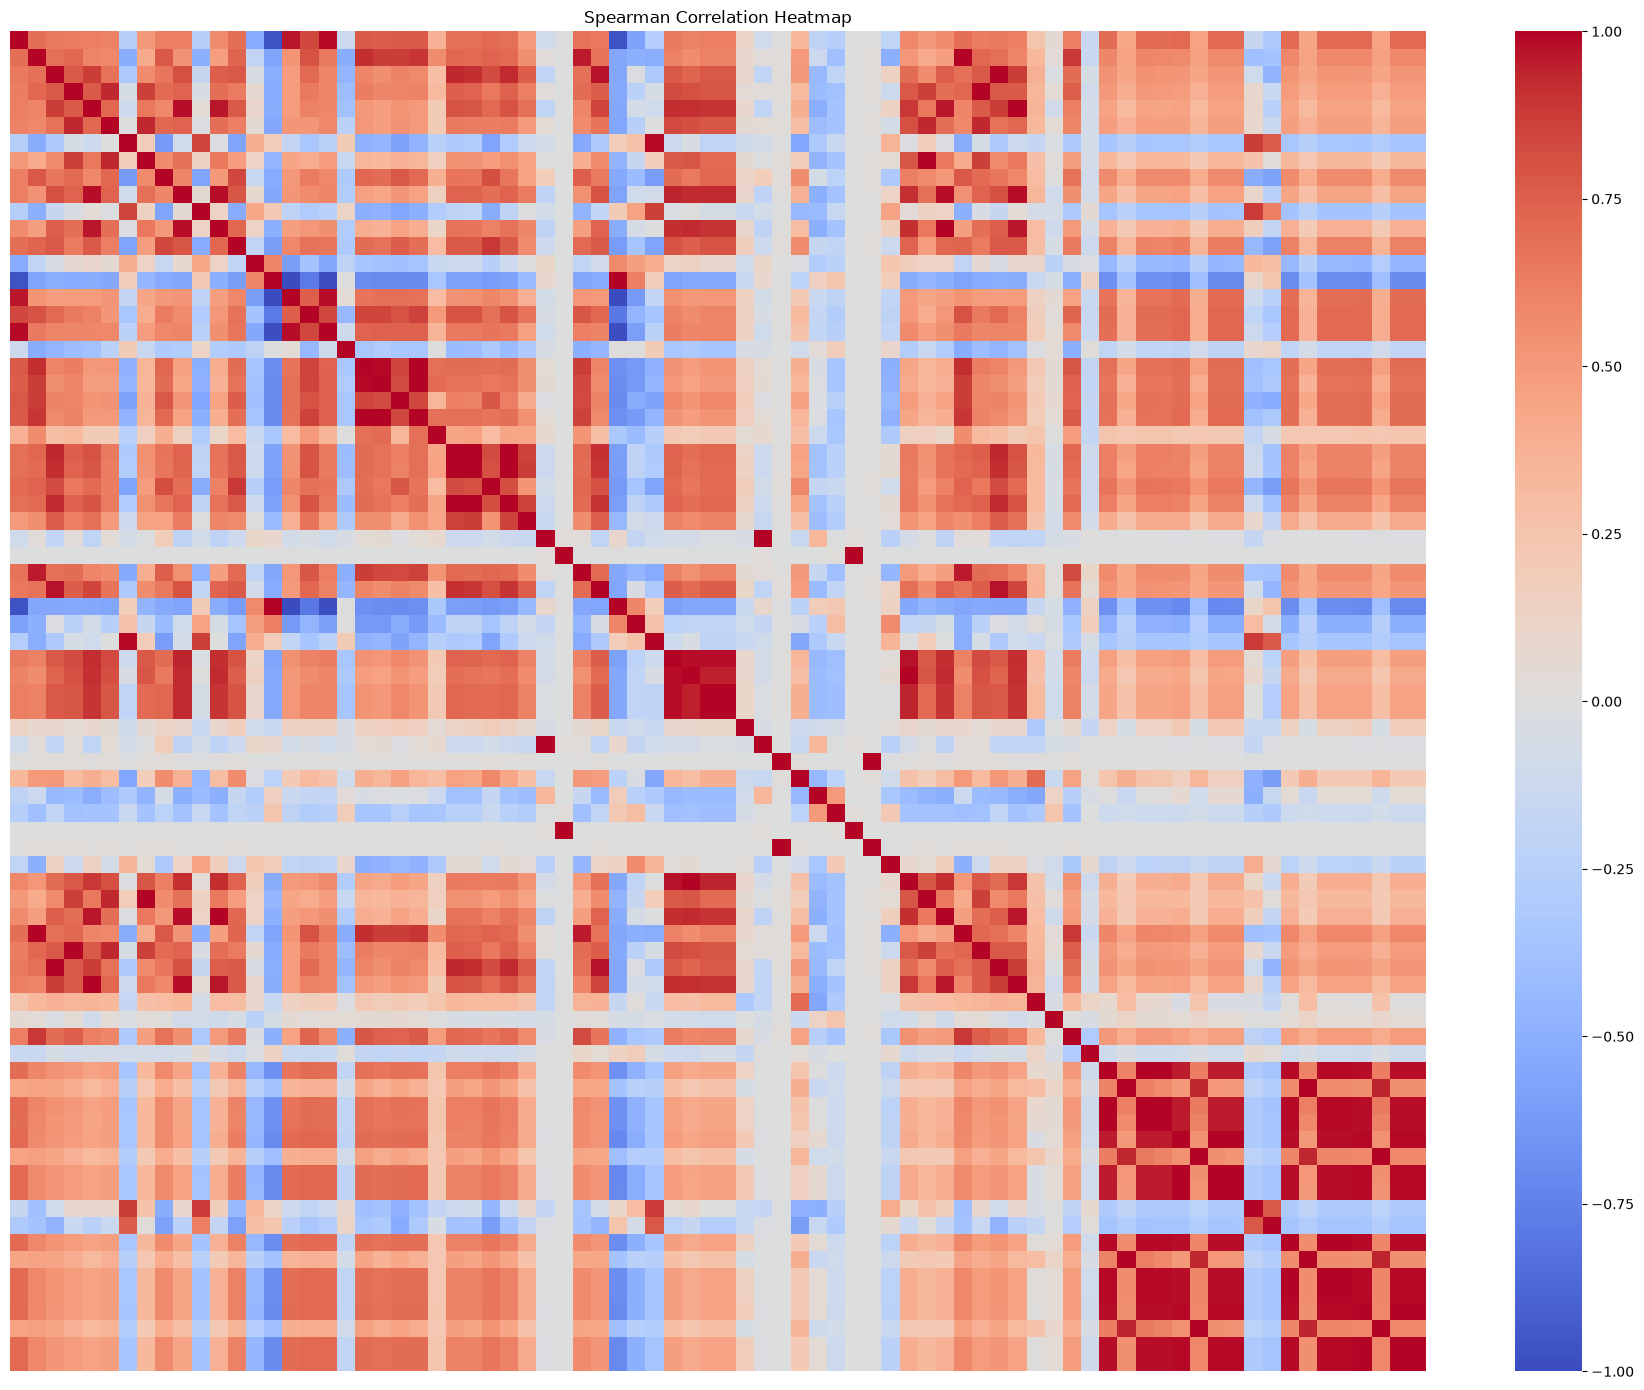

In [40]:
# Calculating Spearman correlation
corr_features = [
    c for c in df_train.select_dtypes(include=np.number).columns
    if c not in [
        "Destination Port",
        "is_attack"
    ]
    and df_train[c].nunique(dropna=True) > 1
]

# Use a sample to reduce computational cost
corr_sample = df_train[corr_features].sample(
    n=min(100_000, len(df_train)),
    random_state=42
)

# Median imputation for correlation calculation
corr_sample = corr_sample.fillna(
    corr_sample.median()
)

# Spearman correlation
spearman_corr = corr_sample.corr(
    method="spearman"
)

plt.figure(figsize=(18, 14))

sns.heatmap(
    spearman_corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=False,
    yticklabels=False
)

plt.title("Spearman Correlation Heatmap")
plt.tight_layout()
plt.show()

In [41]:
# Identifying Highly correlated feature pairs
upper = spearman_corr.where(
    np.triu(
        np.ones(spearman_corr.shape),
        k=1
    ).astype(bool)
)

correlated_pairs = (
    upper.stack()
    .reset_index()
)

correlated_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Spearman Correlation"
]

high_corr_pairs = correlated_pairs[
    correlated_pairs["Spearman Correlation"].abs() > 0.95
].copy()

high_corr_pairs["Absolute Correlation"] = (
    high_corr_pairs["Spearman Correlation"].abs()
)

high_corr_pairs = high_corr_pairs.sort_values(
    "Absolute Correlation",
    ascending=False
)

display(high_corr_pairs.head(50))

print(
    "Number of highly correlated pairs:",
    len(high_corr_pairs)
)

,Feature 1,Feature 2,Spearman Correlation,Absolute Correlation
210,Total Backward Packets,Subflow Bwd Packets,1.000000,1.000000
130,Total Fwd Packets,Subflow Fwd Packets,1.000000,1.000000
596,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000,1.000000
367,Total Length of Bwd Packets,Subflow Bwd Bytes,1.000000,1.000000
287,Total Length of Fwd Packets,Subflow Fwd Bytes,1.000000,1.000000
909,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000,1.000000
3323,RST Flag Count,ECE Flag Count,1.000000,1.000000
2386,Fwd URG Flags,CWE Flag Count,1.000000,1.000000
2303,Fwd PSH Flags,SYN Flag Count,1.000000,1.000000
6005,idle_max_present,idle_min_present,1.000000,1.000000


Number of highly correlated pairs: 114


In [42]:
# Removing Rebundant features
corr_threshold = 0.95

abs_corr = spearman_corr.abs()

remaining_features = list(abs_corr.columns)
removed_corr_features = []

while True:

    current_corr = abs_corr.loc[
        remaining_features,
        remaining_features
    ]

    upper = current_corr.where(
        np.triu(
            np.ones(current_corr.shape),
            k=1
        ).astype(bool)
    )

    pairs = upper.stack()

    if pairs.empty or pairs.max() <= corr_threshold:
        break

    # Find the most highly correlated pair
    feature_1, feature_2 = pairs.idxmax()

    # Average correlation with all other features
    mean_corr = current_corr.mean()

    # Remove the feature with higher average redundancy
    if mean_corr[feature_1] >= mean_corr[feature_2]:
        drop_feature = feature_1
    else:
        drop_feature = feature_2

    remaining_features.remove(drop_feature)
    removed_corr_features.append(drop_feature)


print("Original feature count:", len(corr_features))
print("Remaining feature count:", len(remaining_features))

print("\nRemoved features:")
print(removed_corr_features)

Original feature count: 78
Remaining feature count: 40

Removed features:
['Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Mean', 'Bwd Packet Length Mean', 'Fwd PSH Flags', 'Fwd URG Flags', 'RST Flag Count', 'active_mean_present', 'active_max_present', 'idle_mean_present', 'idle_max_present', 'Packet Length Variance', 'Idle Max', 'Active Max', 'Idle Mean', 'Active Std', 'idle_std_present', 'Bwd IAT Max', 'Active Mean', 'Flow Packets/s', 'Bwd IAT Total', 'Fwd IAT Max', 'Packet Length Mean', 'Fwd Packets/s', 'idle_min_present', 'Fwd IAT Total', 'active_min_present', 'Flow Duration', 'Min Packet Length', 'Bwd Packet Length Max', 'Max Packet Length', 'Flow IAT Max', 'Subflow Bwd Packets', 'Subflow Bwd Bytes', 'Idle Min', 'Subflow Fwd Packets']


In [43]:
# Calculating VIF factors
!pip install statsmodels

from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler

# Sample training observations
vif_sample = df_train[remaining_features].sample(
    n=min(20_000, len(df_train)),
    random_state=42
)

# Impute missing values
vif_sample = vif_sample.fillna(
    vif_sample.median()
)

# Remove any remaining constant columns
vif_features = [
    c for c in vif_sample.columns
    if vif_sample[c].nunique() > 1
]

vif_sample = vif_sample[vif_features]

# Standardise for numerical stability
scaler_vif = StandardScaler()

X_vif = scaler_vif.fit_transform(vif_sample)

# Iteratively remove features with VIF > 10
while True:

    vif_values = pd.Series(
        [
            variance_inflation_factor(X_vif, i)
            for i in range(X_vif.shape[1])
        ],
        index=vif_features
    )

    max_vif = vif_values.max()

    if max_vif <= 10:
        break

    feature_to_remove = vif_values.idxmax()

    print(
        "Removing:",
        feature_to_remove,
        "| VIF:",
        round(max_vif, 2)
    )

    vif_features.remove(feature_to_remove)

    X_vif = scaler_vif.fit_transform(
        vif_sample[vif_features]
    )


vif_final = pd.DataFrame({
    "Feature": vif_features,
    "VIF": [
        variance_inflation_factor(X_vif, i)
        for i in range(X_vif.shape[1])
    ]
})

display(
    vif_final.sort_values(
        "VIF",
        ascending=False
    )
)

print("Features remaining after VIF:", len(vif_features))


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Removing: Fwd IAT Mean | VIF: 537.99
Removing: Flow IAT Std | VIF: 209.36
Removing: Packet Length Std | VIF: 167.67
Removing: Bwd IAT Mean | VIF: 126.24
Removing: forward_unknown | VIF: 96.94
Removing: Avg Bwd Segment Size | VIF: 51.13
Removing: Flow IAT Mean | VIF: 42.16
Removing: Fwd Packet Length Std | VIF: 38.26
Removing: Fwd Header Length | VIF: 11.8
Removing: Avg Fwd Segment Size | VIF: 10.17


,Feature,VIF
14,PSH Flag Count,8.850142
7,Fwd IAT Min,7.757852
9,Bwd IAT Min,7.233454
20,Average Packet Size,6.728755
3,Bwd Packet Length Std,6.428964
28,backward_unknown,6.359511
15,ACK Flag Count,4.708535
6,Fwd IAT Std,3.776818
16,URG Flag Count,2.844146
2,Bwd Packet Length Min,2.643625


Features remaining after VIF: 30


In [44]:
# Saving reduced feature list
selected_features = vif_features.copy()

print("Final selected numerical features:")
for feature in selected_features:
    print(feature)

print("\nTotal selected features:", len(selected_features))

pd.Series(
    selected_features,
    name="Selected_Features"
).to_csv(
    "selected_features.csv",
    index=False
)

Final selected numerical features:
Fwd Packet Length Max
Fwd Packet Length Min
Bwd Packet Length Min
Bwd Packet Length Std
Flow Bytes/s
Flow IAT Min
Fwd IAT Std
Fwd IAT Min
Bwd IAT Std
Bwd IAT Min
Bwd Header Length
Bwd Packets/s
FIN Flag Count
SYN Flag Count
PSH Flag Count
ACK Flag Count
URG Flag Count
CWE Flag Count
ECE Flag Count
Down/Up Ratio
Average Packet Size
Subflow Fwd Bytes
Init_Win_bytes_forward
Init_Win_bytes_backward
act_data_pkt_fwd
min_seg_size_forward
Active Min
Idle Std
backward_unknown
active_std_present

Total selected features: 30


In [45]:
# Grouping Rare Attack classes 

# Defining Attack taxonomy
attack_mapping = {

    # Normal traffic
    "BENIGN": "BENIGN",

    # Denial of Service family
    "DDoS": "DoS_DDoS",
    "DoS Hulk": "DoS_DDoS",
    "DoS GoldenEye": "DoS_DDoS",
    "DoS slowloris": "DoS_DDoS",
    "DoS Slowhttptest": "DoS_DDoS",

    # Reconnaissance
    "PortScan": "Reconnaissance",

    # Brute-force attacks
    "FTP-Patator": "Brute_Force",
    "SSH-Patator": "Brute_Force",
    "Web Attack - Brute Force": "Brute_Force",

    # Web attacks
    "Web Attack - XSS": "Web_Attack",
    "Web Attack - Sql Injection": "Web_Attack",

    # Bot activity
    "Bot": "Bot",

    # Extremely rare classes
    "Heartbleed": "Other_Rare",
    "Infiltration": "Other_Rare"
}

df["Label_grouped"] = df["Label"].map(
    attack_mapping
)

# Check for labels that were not mapped
unmapped = df.loc[
    df["Label_grouped"].isna(),
    "Label"
].unique()

print("Unmapped labels:", unmapped)

assert df["Label_grouped"].notna().all()

Unmapped labels: <ArrowStringArray>
[]
Length: 0, dtype: str


In [46]:
# Comparing original and grouped class distributions
original_counts = df["Label"].value_counts()

grouped_counts = df["Label_grouped"].value_counts()

print("Original class distribution:")
display(original_counts.to_frame("Count"))

print("\nGrouped class distribution:")
display(grouped_counts.to_frame("Count"))

Original class distribution:


,Count
Label,
BENIGN,2069532
DoS Hulk,172688
DDoS,127995
PortScan,90694
DoS GoldenEye,10277
FTP-Patator,5927
DoS slowloris,5374
DoS Slowhttptest,5228
SSH-Patator,3217



Grouped class distribution:


,Count
Label_grouped,
BENIGN,2069532
DoS_DDoS,321562
Reconnaissance,90694
Brute_Force,10614
Bot,1948
Web_Attack,673
Other_Rare,42


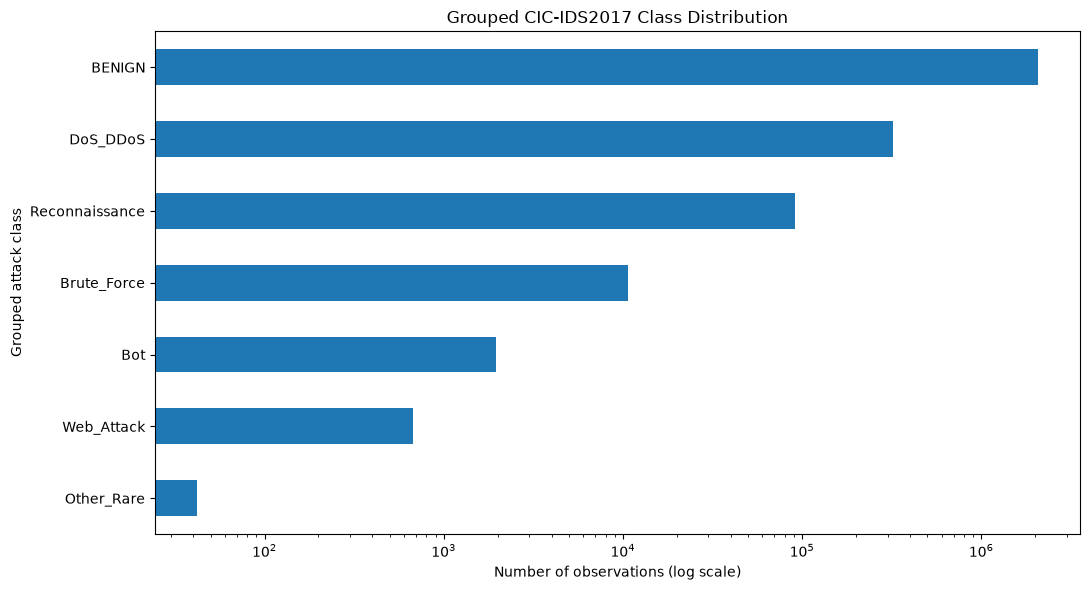

In [47]:
# Visualise the grouped class distribution
plt.figure(figsize=(11, 6))

grouped_counts.sort_values().plot(
    kind="barh",
    logx=True
)

plt.xlabel("Number of observations (log scale)")
plt.ylabel("Grouped attack class")
plt.title("Grouped CIC-IDS2017 Class Distribution")

plt.tight_layout()
plt.show()

In [48]:
# Comparing original and grouped labels
comparison = pd.crosstab(
    df["Label"],
    df["Label_grouped"]
)

display(comparison)

Label_grouped,BENIGN,Bot,Brute_Force,DoS_DDoS,Other_Rare,Reconnaissance,Web_Attack
Label,,,,,,,
BENIGN,2069532,0,0,0,0,0,0
Bot,0,1948,0,0,0,0,0
DDoS,0,0,0,127995,0,0,0
DoS GoldenEye,0,0,0,10277,0,0,0
DoS Hulk,0,0,0,172688,0,0,0
DoS Slowhttptest,0,0,0,5228,0,0,0
DoS slowloris,0,0,0,5374,0,0,0
FTP-Patator,0,0,5927,0,0,0,0
Heartbleed,0,0,0,0,7,0,0


In [49]:
# Create binary and multiclass targets
# Binary classification target
df["Binary_Label"] = (
    df["Label"] != "BENIGN"
).astype("int8")

# Multiclass classification target
df["Multiclass_Label"] = df["Label_grouped"]

print("Binary classification:")
display(df["Binary_Label"].value_counts())

print("\nGrouped multiclass classification:")
display(df["Multiclass_Label"].value_counts())

Binary classification:


Binary_Label
0    2069532
1     425533
Name: count, dtype: int64


Grouped multiclass classification:


Multiclass_Label
BENIGN            2069532
DoS_DDoS           321562
Reconnaissance      90694
Brute_Force         10614
Bot                  1948
Web_Attack            673
Other_Rare             42
Name: count, dtype: int64

In [50]:
# Preparing Modelling dataset
from sklearn.model_selection import train_test_split

# Use grouped multiclass classification
target = "Label_grouped"

# Numerical features selected through Spearman and VIF
numeric_features = selected_features.copy()

# Add engineered binary indicators
engineered_numeric = [
    "forward_unknown",
    "backward_unknown",
    "active_mean_present",
    "active_std_present",
    "active_max_present",
    "active_min_present",
    "idle_mean_present",
    "idle_std_present",
    "idle_max_present",
    "idle_min_present"
]

for col in engineered_numeric:

    if col in df.columns and col not in numeric_features:
        numeric_features.append(col)

# Remove any unavailable columns
numeric_features = [
    c for c in numeric_features
    if c in df.columns
]

# Categorical features
categorical_features = [
    "Destination_Port_Group"
]

# Protocol is a categorical variable, not a continuous measurement
if "Protocol" in df.columns:

    df["Protocol"] = (
        df["Protocol"]
        .astype("string")
    )

    categorical_features.append("Protocol")

# Do not include the raw Destination Port
numeric_features = [
    c for c in numeric_features
    if c != "Destination Port"
]

feature_columns = (
    numeric_features + categorical_features
)

X = df[feature_columns].copy()
y = df[target].copy()

print("Numerical features:", len(numeric_features))
print("Categorical features:", categorical_features)

print("X shape:", X.shape)
print("y shape:", y.shape)

Numerical features: 38
Categorical features: ['Destination_Port_Group']
X shape: (2495065, 39)
y shape: (2495065,)


In [51]:
# Splitting Training and test data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", X_train.shape[0])
print("Testing observations:", X_test.shape[0])

print("\nTraining class distribution:")
display(y_train.value_counts())

print("\nTesting class distribution:")
display(y_test.value_counts())

Training observations: 1996052
Testing observations: 499013

Training class distribution:


Label_grouped
BENIGN            1655626
DoS_DDoS           257250
Reconnaissance      72555
Brute_Force          8491
Bot                  1558
Web_Attack            538
Other_Rare             34
Name: count, dtype: int64


Testing class distribution:


Label_grouped
BENIGN            413906
DoS_DDoS           64312
Reconnaissance     18139
Brute_Force         2123
Bot                  390
Web_Attack           135
Other_Rare             8
Name: count, dtype: int64

In [52]:
# Train/ Test Split

print(X_train[["forward_unknown", "backward_unknown"]].sum())
assert (X_train[["forward_unknown", "backward_unknown"]].sum() > 0).all()

forward_unknown     713511
backward_unknown    954497
dtype: int64


In [53]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    FunctionTransformer,
    RobustScaler,
    OneHotEncoder
)
from sklearn.compose import ColumnTransformer

def signed_log1p(X):

    return np.sign(X) * np.log1p(np.abs(X))


numeric_pipeline = Pipeline(
    steps=[

        (
            "imputer",
            SimpleImputer(strategy="median")
        ),

        (
            "log_transform",
            FunctionTransformer(
                signed_log1p,
                validate=False
            )
        ),

        (
            "scaler",
            RobustScaler()
        )

    ]
)

In [54]:
# Categorical preprocessing pipeline
categorical_pipeline = Pipeline(
    steps=[

        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),

        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )

    ]
)

In [55]:
# Combining the preprocessing steps

preprocessor = ColumnTransformer(

    transformers=[

        (
            "numerical",
            numeric_pipeline,
            numeric_features
        ),

        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )

    ],

    remainder="drop",

    sparse_threshold=1.0
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [56]:
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

logistic_model = Pipeline(

    steps=[

        (
            "preprocessing",
            preprocessor
        ),

        (
            "classifier",
            LogisticRegression(
                C=1.0,
                solver="saga",
                l1_ratio=0.0,
                max_iter=300,
                tol=1e-3,
                class_weight="balanced",
                random_state=42
            )
        )

    ]
)

In [57]:
from sklearn.model_selection import train_test_split

# Take a stratified sample from training data only
X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train,
    y_train,
    train_size=300_000,
    random_state=42,
    stratify=y_train
)

print("Original training size:", X_train.shape)
print("Sampled training size:", X_train_sample.shape)
print("Testing size:", X_test.shape)

print("\nSampled class distribution:")
display(y_train_sample.value_counts())

Original training size: (1996052, 39)
Sampled training size: (300000, 39)
Testing size: (499013, 39)

Sampled class distribution:


Label_grouped
BENIGN            248835
DoS_DDoS           38664
Reconnaissance     10905
Brute_Force         1276
Bot                  234
Web_Attack            81
Other_Rare             5
Name: count, dtype: int64

In [58]:
# Train the revised Logistic Regression model
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),

        ("classifier", LogisticRegression(
            C=1.0,
            solver="saga",
            l1_ratio=0.0,
            max_iter=300,
            tol=1e-3,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

logistic_model.fit(
    X_train_sample,
    y_train_sample
)

print("Model training completed.")

Model training completed.


C:\Users\AGNIPROBHO DAS\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [59]:
# Evaluate using the original test set
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

y_pred = logistic_model.predict(X_test)

print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Macro F1:",
      f1_score(y_test, y_pred, average="macro"))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

Accuracy: 0.9138679753834068
Macro F1: 0.48230998140495485

Classification Report:
                precision    recall  f1-score   support

        BENIGN       1.00      0.90      0.95    413906
           Bot       0.02      0.96      0.05       390
   Brute_Force       0.33      0.86      0.47      2123
      DoS_DDoS       0.86      0.98      0.91     64312
    Other_Rare       0.00      0.62      0.00         8
Reconnaissance       0.89      0.99      0.94     18139
    Web_Attack       0.03      0.94      0.05       135

      accuracy                           0.91    499013
     macro avg       0.45      0.89      0.48    499013
  weighted avg       0.97      0.91      0.94    499013



In [60]:
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

Training data shape: (1996052, 39)
Testing data shape: (499013, 39)

Training labels:
Label_grouped
BENIGN            1655626
DoS_DDoS           257250
Reconnaissance      72555
Brute_Force          8491
Bot                  1558
Web_Attack            538
Other_Rare             34
Name: count, dtype: int64

Testing labels:
Label_grouped
BENIGN            413906
DoS_DDoS           64312
Reconnaissance     18139
Brute_Force         2123
Bot                  390
Web_Attack           135
Other_Rare             8
Name: count, dtype: int64


In [61]:
%pip install psutil
import psutil

print("Total RAM:",
      round(psutil.virtual_memory().total / (1024**3), 2), "GB")

print("Available RAM:",
      round(psutil.virtual_memory().available / (1024**3), 2), "GB")

Note: you may need to restart the kernel to use updated packages.
Total RAM: 15.7 GB
Available RAM: 2.93 GB



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [62]:
import psutil
import os

process = psutil.Process(os.getpid())

print("RAM currently used by Python:",
      round(process.memory_info().rss / (1024**3), 2), "GB")

print("Total system RAM:",
      round(psutil.virtual_memory().total / (1024**3), 2), "GB")

print("Available system RAM:",
      round(psutil.virtual_memory().available / (1024**3), 2), "GB")

RAM currently used by Python: 3.82 GB
Total system RAM: 15.7 GB
Available system RAM: 2.93 GB


In [63]:
print("Feature data types:")
print(X_train.dtypes.value_counts())

print("\nCategorical columns:")
print(X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist())

print("\nNumerical columns:")
print(X_train.select_dtypes(
    include="number"
).columns.tolist())

Feature data types:
float32    28
int8       10
str         1
Name: count, dtype: int64

Categorical columns:
['Destination_Port_Group']

Numerical columns:
['Fwd Packet Length Max', 'Fwd Packet Length Min', 'Bwd Packet Length Min', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow IAT Min', 'Fwd IAT Std', 'Fwd IAT Min', 'Bwd IAT Std', 'Bwd IAT Min', 'Bwd Header Length', 'Bwd Packets/s', 'FIN Flag Count', 'SYN Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Flag Count', 'Down/Up Ratio', 'Average Packet Size', 'Subflow Fwd Bytes', 'Init_Win_bytes_forward', 'Init_Win_bytes_backward', 'act_data_pkt_fwd', 'min_seg_size_forward', 'Active Min', 'Idle Std', 'backward_unknown', 'active_std_present', 'forward_unknown', 'active_mean_present', 'active_max_present', 'active_min_present', 'idle_mean_present', 'idle_std_present', 'idle_max_present', 'idle_min_present']


C:\Users\AGNIPROBHO DAS\AppData\Local\Temp\ipykernel_23020\1415158658.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(X_train.select_dtypes(


In [64]:
import numpy as np
from scipy import sparse

X_sample = X_train.sample(
    n=50_000,
    random_state=42
)

X_sample_transformed = preprocessor.fit_transform(X_sample)

if sparse.issparse(X_sample_transformed):
    memory_gb = (
        X_sample_transformed.data.nbytes
        + X_sample_transformed.indices.nbytes
        + X_sample_transformed.indptr.nbytes
    ) / (1024**3)
else:
    memory_gb = X_sample_transformed.nbytes / (1024**3)

print("Transformed shape:", X_sample_transformed.shape)
print("Sparse matrix:", sparse.issparse(X_sample_transformed))
print("Memory required:", round(memory_gb, 3), "GB")

Transformed shape: (50000, 54)
Sparse matrix: True
Memory required: 0.01 GB


In [65]:
import psutil

print("Available RAM:",
      round(psutil.virtual_memory().available / (1024**3), 2),
      "GB")

Available RAM: 2.94 GB


In [66]:
log_reg = LogisticRegression(
    C=1.0,
    solver="saga",
    l1_ratio=0.0,
    max_iter=500,
    tol=1e-3,
    class_weight="balanced",
    random_state=42
)

In [67]:
# Configure the model
import time
import psutil
import os

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(
    C=1.0,
    solver="saga",
    l1_ratio=0.0,
    max_iter=100,
    tol=1e-3,
    class_weight="balanced",
    random_state=42
)

log_reg_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", log_reg)
])

In [68]:
#Training on the complete training dataset
process = psutil.Process(os.getpid())

start_time = time.time()

print("Full training started...")

log_reg_pipeline.fit(X_train, y_train)

end_time = time.time()

print("\nTraining completed.")

print("Time taken:",
      round((end_time - start_time) / 60, 2), "minutes")

print("Python memory usage:",
      round(process.memory_info().rss / (1024**3), 2), "GB")

print("Available system RAM:",
      round(psutil.virtual_memory().available / (1024**3), 2), "GB")

print("Iterations:",
      log_reg_pipeline.named_steps["classifier"].n_iter_)

Full training started...

Training completed.
Time taken: 7.59 minutes
Python memory usage: 3.84 GB
Available system RAM: 3.36 GB
Iterations: [100]


C:\Users\AGNIPROBHO DAS\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [69]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predict on the untouched test set
y_pred = log_reg_pipeline.predict(X_test)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Macro F1-score:",
      f1_score(y_test, y_pred, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8992150505097062
Macro F1-score: 0.4997809104573614

Classification Report:
                precision    recall  f1-score   support

        BENIGN       0.99      0.89      0.94    413906
           Bot       0.02      0.99      0.04       390
   Brute_Force       0.46      0.86      0.60      2123
      DoS_DDoS       0.95      0.94      0.94     64312
    Other_Rare       0.00      0.88      0.00         8
Reconnaissance       0.90      0.99      0.95     18139
    Web_Attack       0.02      1.00      0.03       135

      accuracy                           0.90    499013
     macro avg       0.48      0.93      0.50    499013
  weighted avg       0.98      0.90      0.94    499013


Confusion Matrix:
[[368167  17548   2090   3326  13790   1506   7479]
 [     2    388      0      0      0      0      0]
 [     3      0   1819      8      0      1    292]
 [  1991      0     53  60206   1163    419    480]
 [     0      1      0      0      7      0      0]
 [    84      

In [70]:
log_reg_unbalanced = LogisticRegression(
    C=1.0,
    solver="saga",
    l1_ratio=0.0,
    max_iter=100,
    tol=1e-3,
    class_weight=None,
    random_state=42
)

log_reg_pipeline_unbalanced = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", log_reg_unbalanced)
])

log_reg_pipeline_unbalanced.fit(X_train, y_train)

C:\Users\AGNIPROBHO DAS\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](7,)","['BENIGN','Bot','Brute_Force',...,'Other_Rare','Reconnaissance', 'Web_Attack']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](39,)","['Fwd Packet Length Max','Fwd Packet Length Min','Bwd Packet Length Min', ...,'idle_max_present','idle_min_present','Destination_Port_Group']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,39
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,t

In [71]:
# Evaluate
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predictions on the same untouched test set
y_pred_unbalanced = log_reg_pipeline_unbalanced.predict(X_test)

# Evaluation
print("Accuracy:",
      accuracy_score(y_test, y_pred_unbalanced))

print("Macro F1-score:",
      f1_score(y_test, y_pred_unbalanced, average="macro"))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_unbalanced,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_unbalanced))

Accuracy: 0.9945211848188323
Macro F1-score: 0.6854864760372481

Classification Report:
                precision    recall  f1-score   support

        BENIGN       1.00      1.00      1.00    413906
           Bot       0.79      0.40      0.53       390
   Brute_Force       0.95      0.84      0.89      2123
      DoS_DDoS       0.99      0.99      0.99     64312
    Other_Rare       1.00      0.25      0.40         8
Reconnaissance       0.99      1.00      0.99     18139
    Web_Attack       0.00      0.00      0.00       135

      accuracy                           0.99    499013
     macro avg       0.82      0.64      0.69    499013
  weighted avg       0.99      0.99      0.99    499013


Confusion Matrix:
[[412772     41     91    778      0    224      0]
 [   234    156      0      0      0      0      0]
 [   336      0   1778      9      0      0      0]
 [   812      0      0  63494      0      6      0]
 [     6      0      0      0      2      0      0]
 [    45      

In [72]:
# Validation-based selection of class weights (test set is NOT used here)
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.20, stratify=y_train, random_state=42
)

def cw(benign, dos, recon, brute, bot, web, rare):
    return {"BENIGN": benign, "DoS_DDoS": dos, "Reconnaissance": recon,
            "Brute_Force": brute, "Bot": bot, "Web_Attack": web, "Other_Rare": rare}

candidate_weights = {
    "none":   None,
    "mild":   cw(1, 1, 1, 2, 5, 5, 5),
    "custom": cw(1, 1, 1, 3, 10, 10, 10),     # your original choice
    "strong": cw(1, 1, 1, 5, 20, 20, 20),
}

val_scores = {}
for name, weights in candidate_weights.items():
    pipe = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(
            C=1.0, solver="saga", l1_ratio=0.0, max_iter=100, tol=1e-3,
            class_weight=weights, random_state=42)),
    ])
    pipe.fit(X_fit, y_fit)
    val_scores[name] = f1_score(y_val, pipe.predict(X_val), average="macro")
    print(f"{name:7s} validation macro-F1 = {val_scores[name]:.4f}")

best_name = max(val_scores, key=val_scores.get)
custom_weights = candidate_weights[best_name]     # used by the next cell (In[74])
print("Selected:", best_name, custom_weights)

C:\Users\AGNIPROBHO DAS\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


none    validation macro-F1 = 0.6902


C:\Users\AGNIPROBHO DAS\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


mild    validation macro-F1 = 0.8049


C:\Users\AGNIPROBHO DAS\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


custom  validation macro-F1 = 0.8019


C:\Users\AGNIPROBHO DAS\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


strong  validation macro-F1 = 0.7529
Selected: mild {'BENIGN': 1, 'DoS_DDoS': 1, 'Reconnaissance': 1, 'Brute_Force': 2, 'Bot': 5, 'Web_Attack': 5, 'Other_Rare': 5}


In [73]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Custom-weighted Logistic Regression
log_reg_custom = LogisticRegression(
    C=1.0,
    solver="saga",
    l1_ratio=0.0,
    max_iter=100,
    tol=1e-3,
    class_weight=custom_weights,
    random_state=42
)

# Complete pipeline
log_reg_pipeline_custom = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", log_reg_custom)
])

# Train on the full training dataset
log_reg_pipeline_custom.fit(X_train, y_train)

print("Custom-weighted training completed.")

Custom-weighted training completed.


C:\Users\AGNIPROBHO DAS\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [74]:
# Evaluate on the test dataset

y_pred_custom = log_reg_pipeline_custom.predict(X_test)

print("Accuracy:",
      accuracy_score(y_test, y_pred_custom))

print("Macro F1-score:",
      f1_score(y_test, y_pred_custom, average="macro"))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_custom,
    zero_division=0
))

Accuracy: 0.9945732876698603
Macro F1-score: 0.8067401413115235

Classification Report:
                precision    recall  f1-score   support

        BENIGN       1.00      1.00      1.00    413906
           Bot       0.58      0.57      0.58       390
   Brute_Force       0.94      0.85      0.89      2123
      DoS_DDoS       0.99      0.99      0.99     64312
    Other_Rare       1.00      0.62      0.77         8
Reconnaissance       0.99      1.00      0.99     18139
    Web_Attack       0.28      0.89      0.43       135

      accuracy                           0.99    499013
     macro avg       0.83      0.85      0.81    499013
  weighted avg       0.99      0.99      0.99    499013



In [75]:
# Evaluating the custom-weighted model
y_pred_custom = log_reg_pipeline_custom.predict(X_test)

print("Accuracy:",
      round(accuracy_score(y_test, y_pred_custom), 4))

print("Macro F1:",
      round(f1_score(
          y_test,
          y_pred_custom,
          average="macro"
      ), 4))

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_custom,
        zero_division=0
    )
)

Accuracy: 0.9946
Macro F1: 0.8067

Classification Report:

                precision    recall  f1-score   support

        BENIGN       1.00      1.00      1.00    413906
           Bot       0.58      0.57      0.58       390
   Brute_Force       0.94      0.85      0.89      2123
      DoS_DDoS       0.99      0.99      0.99     64312
    Other_Rare       1.00      0.62      0.77         8
Reconnaissance       0.99      1.00      0.99     18139
    Web_Attack       0.28      0.89      0.43       135

      accuracy                           0.99    499013
     macro avg       0.83      0.85      0.81    499013
  weighted avg       0.99      0.99      0.99    499013



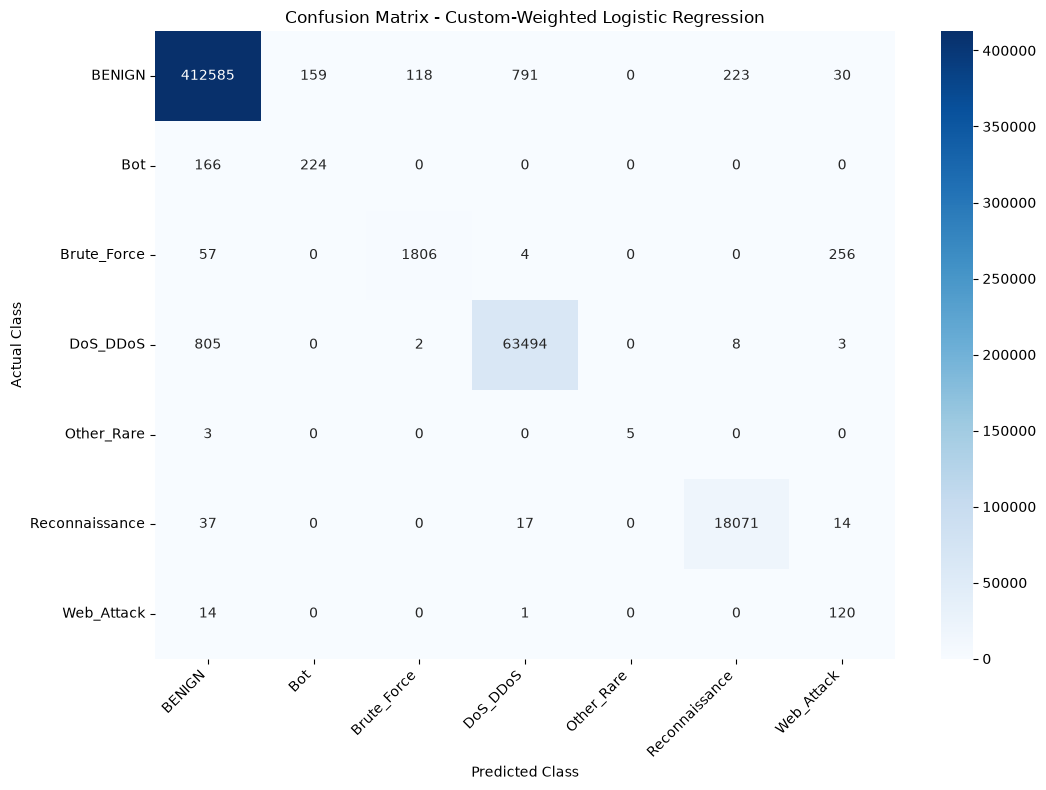

In [76]:
# Plotting the confusion matrix

cm = confusion_matrix(
    y_test,
    y_pred_custom,
    labels=log_reg_pipeline_custom.classes_
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=log_reg_pipeline_custom.classes_,
    yticklabels=log_reg_pipeline_custom.classes_
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title(
    "Confusion Matrix - Custom-Weighted Logistic Regression"
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

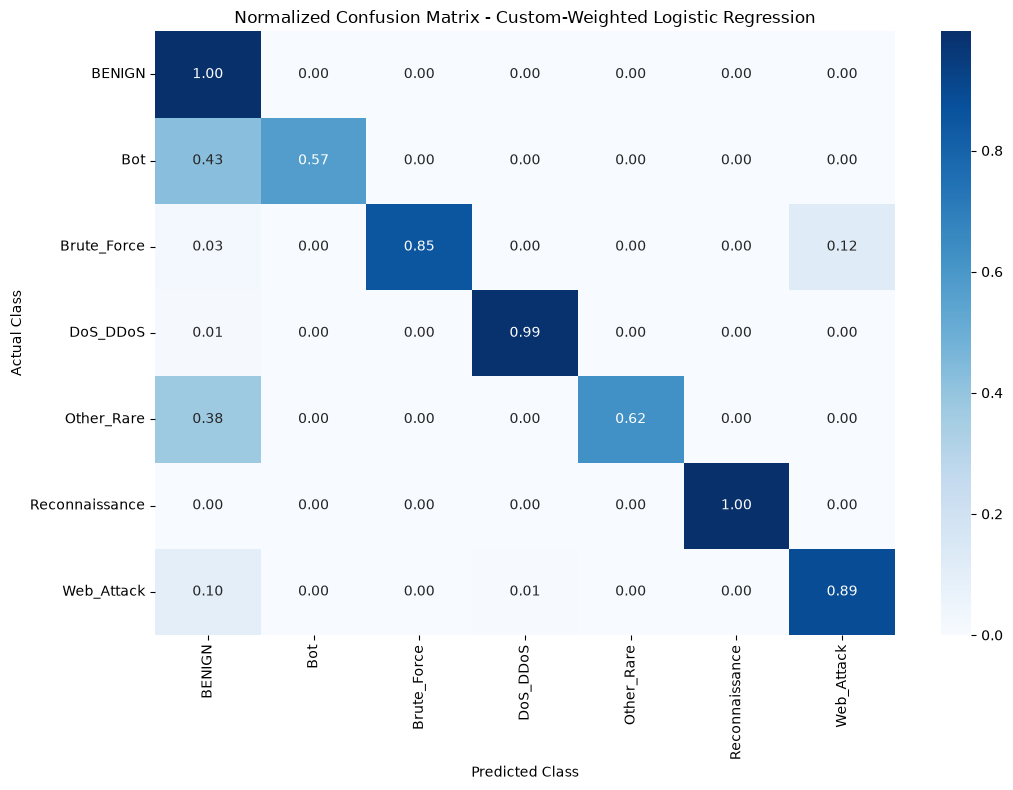

In [77]:
# Normalised error matrix
cm_normalized = confusion_matrix(
    y_test,
    y_pred_custom,
    labels=log_reg_pipeline_custom.classes_,
    normalize="true"
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=log_reg_pipeline_custom.classes_,
    yticklabels=log_reg_pipeline_custom.classes_
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title(
    "Normalized Confusion Matrix - Custom-Weighted Logistic Regression"
)

plt.tight_layout()
plt.show()